# Predicting wildfire persistence, spread and ignition in the Pantanal
### A guided walkthrough of the whole project

**Author:** Abdelwahab LAKSIRI
**Supervisor:** Prof. Marcio CATALDI
**Host laboratory:** LAMMOC (Climate System Monitoring and Modeling Laboratory), Universidade Federal Fluminense (UFF), Rio de Janeiro, Brazil
**Home institution:** EMINES (School of Industrial Management), Université Mohammed VI Polytechnique (UM6P), Morocco

---

**What this notebook is.** One place that walks through everything done in this project, in the order it was done. It loads the project's own data and results, re-runs the analyses that are quick, and explains every step in plain language. No background in data science is assumed. The written report (`report/report.pdf`) tells the same story in prose; this notebook shows the data and the computations behind it.

**How to read it.** Text cells explain; code cells do the work. You can follow the story by reading only the text and the outputs. Each result is labelled:

- **[live]**: computed right now from the data on disk;
- **[saved]**: loaded from a results file that one of the project's scripts wrote. Set `RECOMPUTE = True` in the setup cell to redo these from scratch.

**Running time.** About 3 to 5 minutes as delivered. With `RECOMPUTE = True`, about an hour, because the large experiments train several hundred models.

### Contents
0. Setup
1. The question and the plan
2. A short primer: how to judge a forecast
3. The data
4. Stage 0: auditing the laboratory's daily model
5. Stage 1: the INPE-based model with hourly weather (2019–2024)
6. Stage 2: a truly hourly target with GOES-16 (2024)
7. Stage 3: getting spread right at 2 km, and separating ignition
8. Does weather matter? The paired test
9. The scoreboard
10. Problems found and fixed
11. Limitations and next steps
Appendix A: rebuilding everything from raw data
Appendix B: glossary

## 0. Setup

This cell loads the Python libraries, finds the project folders, and sets two switches:

- `RECOMPUTE`: `False` loads the heavy experiments from saved results; `True` re-runs them.
- `N_SEEDS`: how many times each experiment is repeated with a different random seed (5 everywhere in the project).

It also makes the project's own scripts importable. The feature lists and model settings used below come straight from those scripts, so this notebook and the scripts cannot drift apart.

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")

# ---- switches -------------------------------------------------------
RECOMPUTE = False   # True = re-run the heavy experiments (about an hour)
N_SEEDS = 5         # repetitions per experiment, as in the project scripts

# ---- folders ----------------------------------------------------------
def find_project_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "hourly_model").is_dir() and (p / "goes_hourly_model").is_dir():
            return p
    raise FileNotFoundError("Open this notebook from inside the 'Wild Fire Project' folder.")

PROJECT = find_project_root()
HOURLY = PROJECT / "hourly_model"          # stage 1: INPE-based model
GOES = PROJECT / "goes_hourly_model"       # stages 2-3: GOES-16 models
FIGS = PROJECT / "report" / "figures"      # polished figures used in the report
sys.path[:0] = [str(HOURLY), str(GOES)]    # make the project scripts importable

# ---- display -----------------------------------------------------------
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
GOES_C, INPE_C, FIRE_C, GOOD_C = "#1565c0", "#6a5f7a", "#d84315", "#2e7d32"

def show_figure(name, width=900):
    # display one of the report's polished figures
    display(Image(filename=str(FIGS / name), width=width))

# ---- check that every input exists ----------------------------------
needed = {
    "INPE hotspots 2019-2024": HOURLY / "data" / "fire_events_hourly_regional_2019_2024.csv",
    "ERA5 hourly weather": HOURLY / "data" / "era5_hourly_2019_2024.nc",
    "INPE model table": HOURLY / "data" / "hourly_ml_table_pantanal.parquet",
    "XHWI heatwave index": PROJECT / "xhwi_era5_hourly_2024.nc",
    "Daily model table": PROJECT / "tabela_ml_wind.parquet",
    "Daily model test predictions": PROJECT / "results" / "pantanal_only" / "predicoes_finais_teste_wind.csv",
    "GOES 28 km model table": GOES / "data" / "goes_model_table_2024.parquet",
    "GOES 2 km spread table": GOES / "data" / "goes_spread_2km_2024_01-12.parquet",
    "GOES ignition table": GOES / "data" / "goes_ignition_2024_01-12.parquet",
}
status = pd.DataFrame({"file": [p.relative_to(PROJECT).as_posix() for p in needed.values()],
                       "found": [p.exists() for p in needed.values()]}, index=list(needed))
display(status)
assert status.found.all(), "Some inputs are missing; see Appendix A to rebuild them."
print(f"Project folder: {PROJECT}")

,file,found
INPE hotspots 2019-2024,hourly_model/data/fire_events_hourly_regional_...,True
ERA5 hourly weather,hourly_model/data/era5_hourly_2019_2024.nc,True
INPE model table,hourly_model/data/hourly_ml_table_pantanal.par...,True
XHWI heatwave index,xhwi_era5_hourly_2024.nc,True
Daily model table,tabela_ml_wind.parquet,True
Daily model test predictions,results/pantanal_only/predicoes_finais_teste_w...,True
GOES 28 km model table,goes_hourly_model/data/goes_model_table_2024.p...,True
GOES 2 km spread table,goes_hourly_model/data/goes_spread_2km_2024_01...,True
GOES ignition table,goes_hourly_model/data/goes_ignition_2024_01-1...,True


Project folder: C:\Users\PC\Downloads\Wild Fire Project


## 1. The question and the plan

The **Pantanal** is the world's largest tropical wetland, mostly in the Brazilian states of Mato Grosso (MT) and Mato Grosso do Sul (MS). Every dry season (roughly June to October) its vegetation dries out and burns. Most fires are started by people and then escape. 2020 and 2024 were extreme fire years.

The laboratory already had a **daily** machine-learning model. For each fire seen by satellite on a given day, it predicted two things for the next day:

- **Persistence:** will this fire still be burning?
- **Spread (propagation):** will fire appear around it?

The internship had three goals: build an **hourly** version, evaluate it honestly, and answer a question that kept coming up: **how much does the weather actually matter, and for which kind of fire behaviour?**

The work went through four stages. Each one answered a question and exposed the problem that motivated the next.

| Stage | Data | Target | Main finding | Problem it exposed |
|---|---|---|---|---|
| 0. Audit the daily model | INPE, daily | next day | its 0.93 persistence score is mostly an artefact of how the table was filtered | needed a cleaner design |
| 1. Hourly weather | INPE + hourly ERA5, 2019–2024 | next overpass (~24 h) | persistence ROC-AUC 0.67; hourly wind helps | INPE sees the Pantanal once a day, so the target cannot be hourly |
| 2. Hourly target | GOES-16 + ERA5, 2024, 28 km cells | next hour | 1-hour persistence ROC-AUC 0.83 | the 28 km "spread" target fails physical checks |
| 3. Native resolution | GOES-16 at 2 km | next hour | spread 0.75, ignition 0.81; weather matters only for spread | (limitations, Section 11) |

The rest of this notebook follows these stages one by one.

## 2. A short primer: how to judge a forecast

Every model in this project answers a **yes/no question** ("will this fire still burn in an hour?") and outputs a **probability**. This section explains, with toy numbers, the three ideas needed to read every result that follows.

### 2.1 The base rate, and why accuracy misleads

The **base rate** (also called *prevalence*) is how often the event happens. If 70% of burning fires are still burning an hour later, a "model" that always answers *yes* is right 70% of the time while having learned nothing.

In [2]:
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

rng = np.random.default_rng(0)
n = 20_000
y = (rng.random(n) < 0.70).astype(int)      # 70% of fires survive the hour
always_yes = np.ones(n)

print(f"Base rate                    : {y.mean():.0%}")
print(f"'Always yes' accuracy        : {accuracy_score(y, always_yes):.0%}   <- looks good, learned nothing")
print(f"'Always yes' ROC-AUC         : {roc_auc_score(y, always_yes):.2f}   <- correctly reports: no skill")

Base rate                    : 70%
'Always yes' accuracy        : 70%   <- looks good, learned nothing
'Always yes' ROC-AUC         : 0.50   <- correctly reports: no skill


### 2.2 ROC-AUC, PR-AUC and lift

**ROC-AUC** answers: *if I pick one case where the event happened and one where it did not, how often does the model give the higher probability to the right one?* 0.5 means coin flip; 1.0 means perfect ranking. It does not depend on the base rate, which is why it is the main score for comparing models of events with very different frequencies.

**PR-AUC** (area under the precision–recall curve) asks: *when the model raises an alarm, how often is it real?* Its no-skill value is the base rate itself, not 0.5. So it must always be read next to the base rate. The **lift** is PR-AUC divided by the base rate: how many times better than random the alarms are.

Below, the same weak signal is applied to a common event (base rate 30%) and a rare one (5%). ROC-AUC stays about the same; PR-AUC drops with the base rate, while the lift goes up.

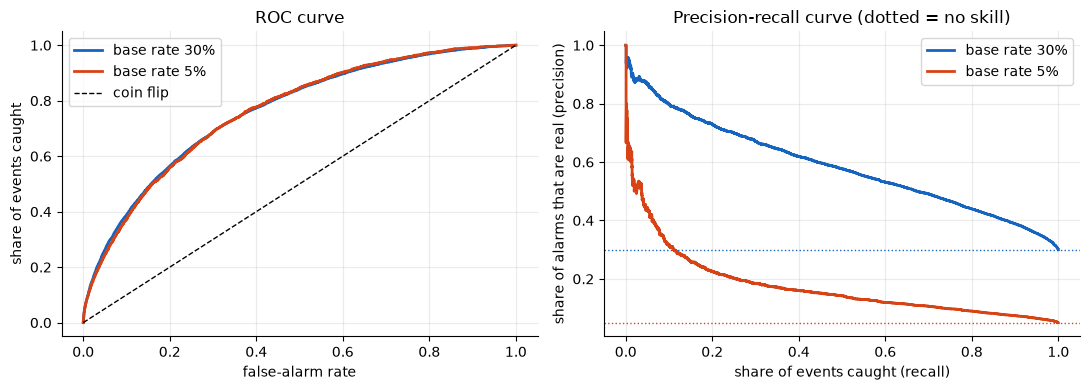

,ROC-AUC,PR-AUC,lift
base rate,,,
0.3000,0.7619,0.5865,1.9551
0.0500,0.7614,0.1739,3.4788


In [3]:
def toy(base_rate, strength=1.0, n=50_000, seed=1):
    r = np.random.default_rng(seed)
    y = (r.random(n) < base_rate).astype(int)
    score = strength * y + r.normal(0, 1, n)      # a real but noisy signal
    return y, score

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rows = []
for base, col in [(0.30, GOES_C), (0.05, FIRE_C)]:
    y, s = toy(base)
    roc, pr = roc_auc_score(y, s), average_precision_score(y, s)
    rows.append({"base rate": base, "ROC-AUC": roc, "PR-AUC": pr, "lift": pr / base})
    fpr, tpr, _ = roc_curve(y, s)
    prec, rec, _ = precision_recall_curve(y, s)
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"base rate {base:.0%}")
    axes[1].plot(rec, prec, color=col, lw=2, label=f"base rate {base:.0%}")
    axes[1].axhline(base, color=col, ls=":", lw=1)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="coin flip")
axes[0].set(title="ROC curve", xlabel="false-alarm rate", ylabel="share of events caught")
axes[1].set(title="Precision-recall curve (dotted = no skill)", xlabel="share of events caught (recall)",
            ylabel="share of alarms that are real (precision)")
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("base rate"))

### 2.3 Is a difference real? Seeds, noise and the t-test

Training involves randomness. A **seed** fixes it so a run can be repeated exactly. Re-running the same model with different seeds shows how much the score moves **by chance alone**: the *noise floor*. A difference smaller than the noise floor means nothing.

Two tools are used throughout:

- **Effect size in units of noise (σ):** the improvement divided by the seed-to-seed spread. Below about 2σ, claim nothing; above 3σ, the effect is clearly real.
- **The paired t-test:** when two models are compared on the *same* test months, the month-by-month differences are averaged and divided by their uncertainty: $t = \bar{d} / (s_d/\sqrt{n})$. The **p-value** is the probability of a difference at least this large if there were truly no effect. A small p (below 0.05 by convention) means "unlikely to be chance". A large p does **not** prove there is no effect; it means the data cannot tell the effect apart from zero.

Section 5.7 shows the noise floor on real data, and Section 8 runs the t-test step by step.

## 3. The data

| Dataset | What it is | Resolution | Used for |
|---|---|---|---|
| INPE Programa Queimadas, reference satellite (`Brasil_sat_ref`) | Fire detections from Brazil's National Institute for Space Research, using one afternoon polar-orbiting satellite so counts are comparable across years | ~1 km, once a day | Stages 0–1 |
| ERA5 hourly single levels | Reanalysis from ECMWF / Copernicus: 2 m temperature and dew point, 10 m wind | 0.25° (~28 km), hourly | all stages |
| XHWI (Extreme Heatwave Index) | Hourly heatwave index produced by LAMMOC/UFF (RiskClima project) | 0.25°, hourly, 2024 only | tested, not used |
| Atmospheric blocking series | Daily counts of blocking events, from the laboratory | daily | Stage 1 |
| SACZ series | Daily South Atlantic Convergence Zone indicators, from the laboratory | daily | Stage 1 |
| GOES-16 ABI L2 Fire/Hot Spot Characterization (`ABI-L2-FDCF`) | NOAA geostationary fire product: fire mask, fire power, area, temperature | ~2 km, every 10 min (1 scan/hour used) | Stages 2–3 |

All models share one rectangular domain, 25°S–13°S and 60°W–53°W, which contains the whole Brazilian Pantanal (49 × 29 ERA5 cells). The figure below shows it.

**Important:** the INPE-based models use only detections that INPE labels *Pantanal biome*. The GOES-16 models use *every* fire inside the rectangle, which also includes Cerrado savanna and parts of Bolivia and Paraguay. As the right panel shows, the densest burning in 2024 was on the western edge, toward Bolivia.

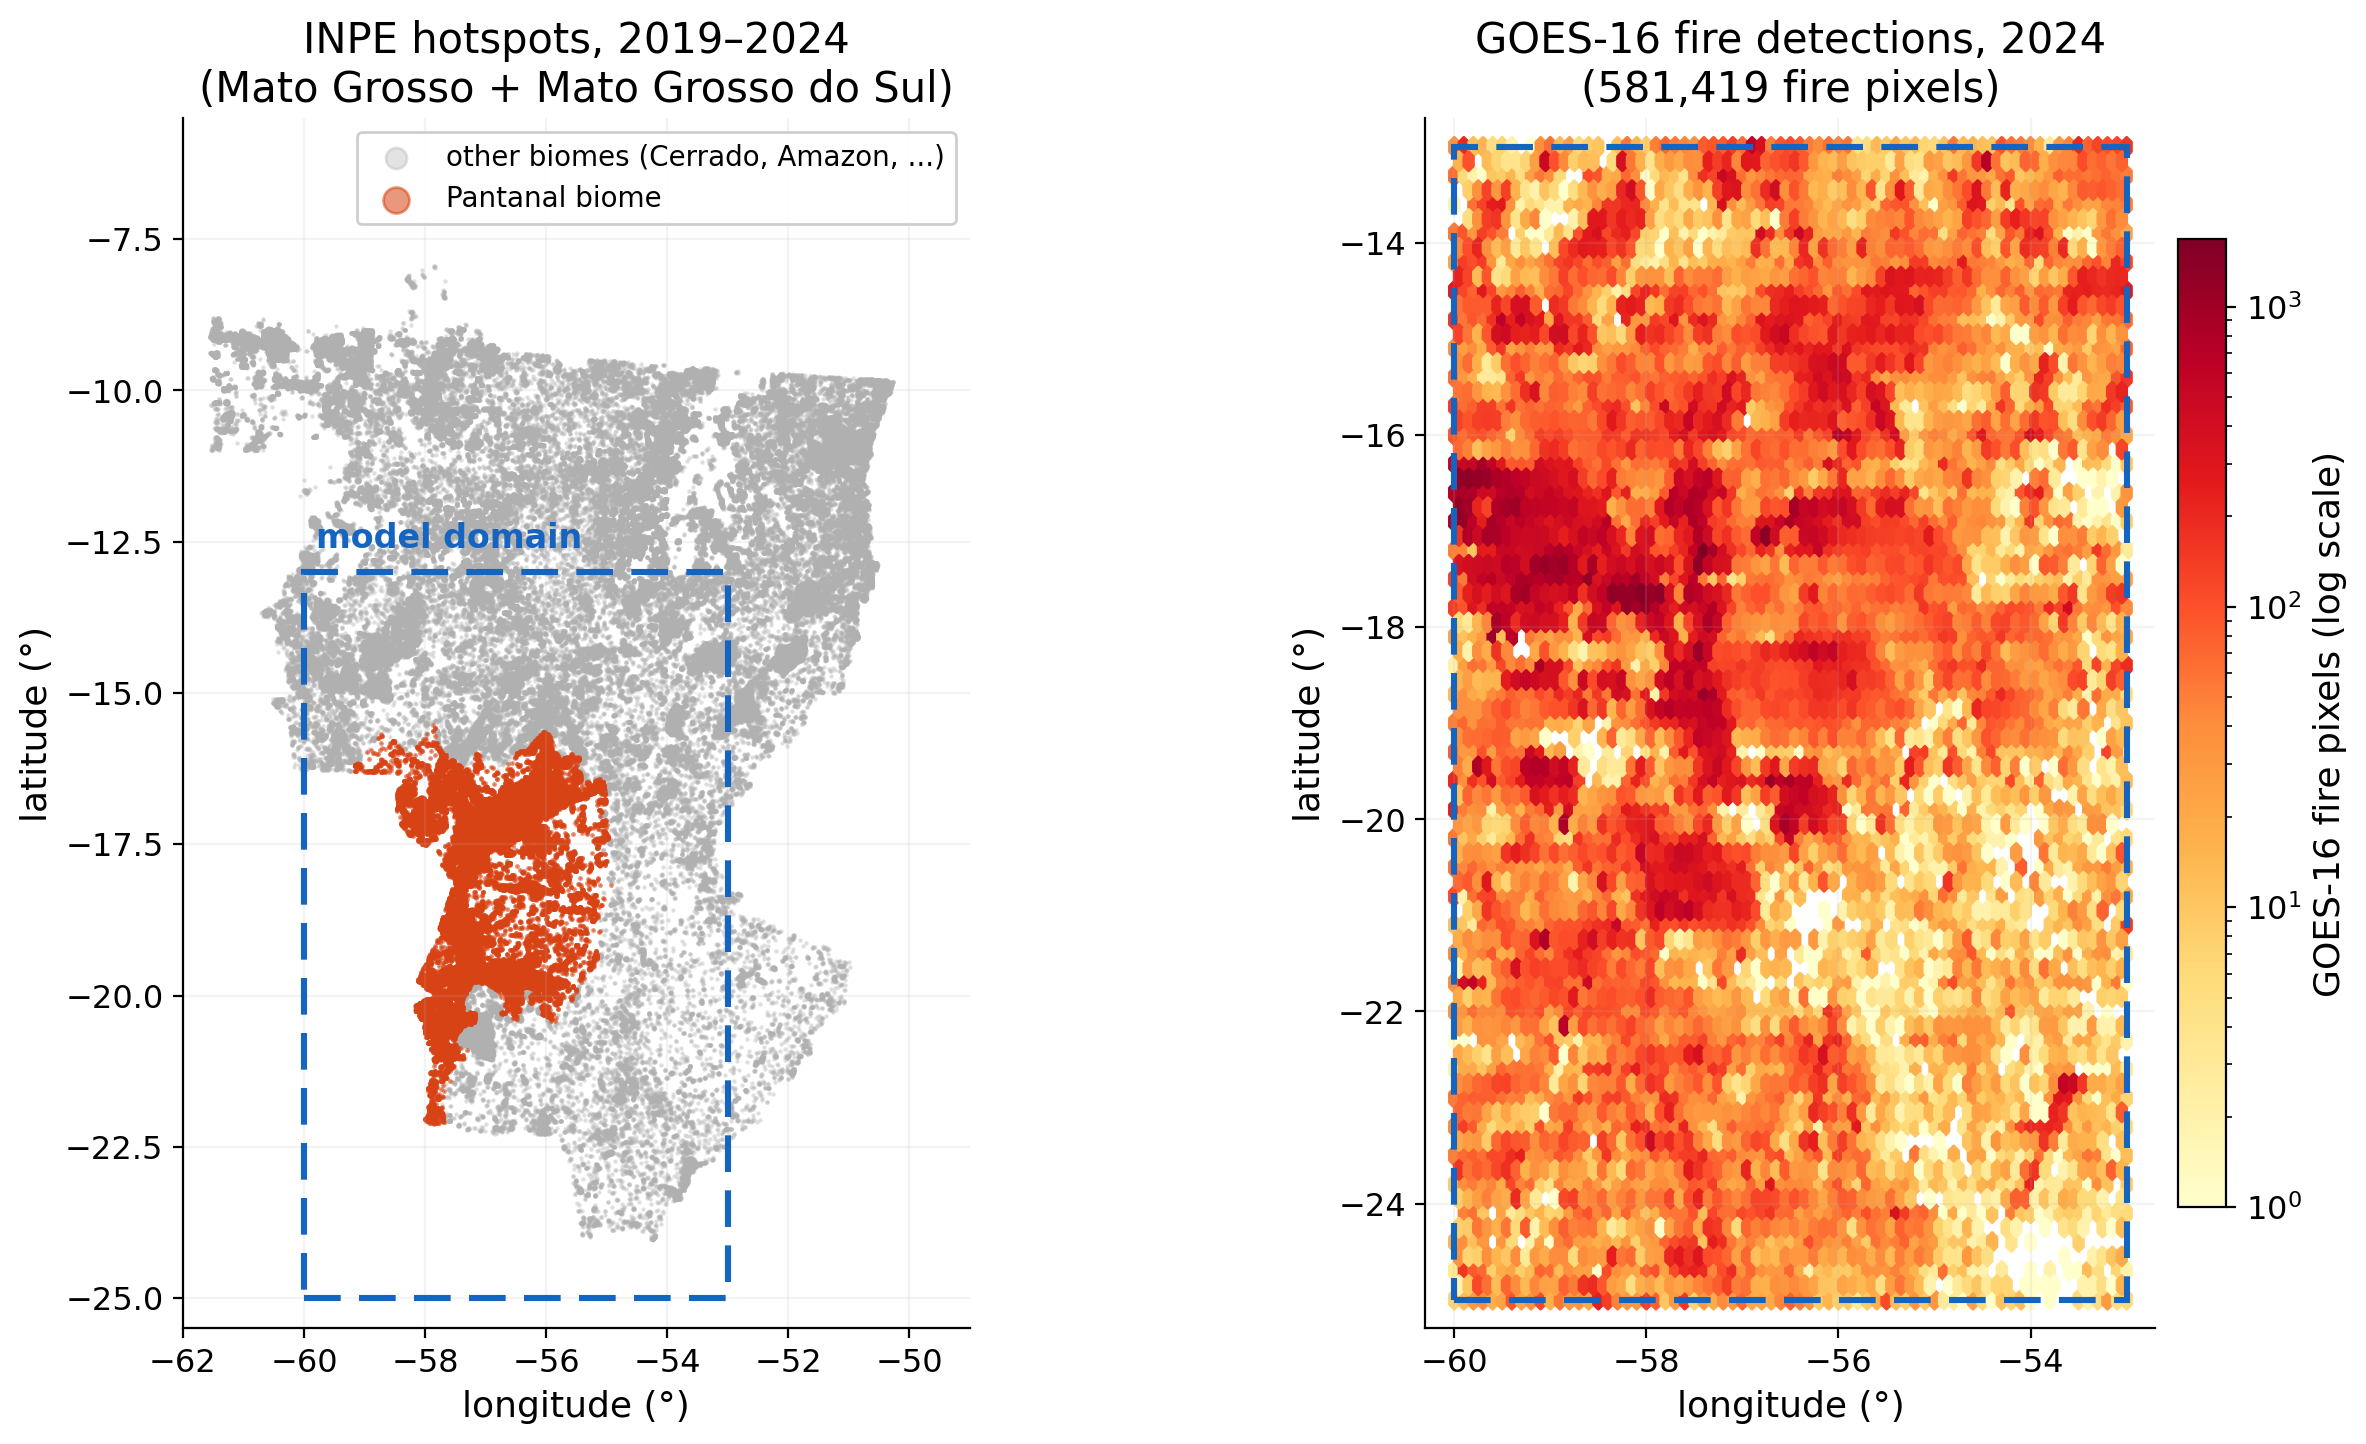

In [4]:
show_figure("fig_study_area.png")

### 3.1 INPE fire detections

The hotspot file covers Mato Grosso and Mato Grosso do Sul for 2019–2024. Each row is one detection (a ~1 km pixel flagged as burning). Detections are kept for the whole two states, not only the Pantanal, for a reason explained in Section 5.2.

In [5]:
inpe = pd.read_csv(HOURLY / "data" / "fire_events_hourly_regional_2019_2024.csv",
                   parse_dates=["detection_hour"])
# the source file stores two accented biome names with a broken character; restore them for display
inpe["biome"] = inpe["biome"].replace({"Amaz\ufffdnia": "Amazônia", "Mata Atl\ufffdntica": "Mata Atlântica"})
pant = inpe[inpe.biome == "Pantanal"]

print(f"[live] {len(inpe):,} detections in MT + MS, 2019-2024; {len(pant):,} of them in the Pantanal biome\n")
display(inpe.biome.value_counts().rename("detections").to_frame())
display(inpe.head(3))

[live] 255,758 detections in MT + MS, 2019-2024; 63,114 of them in the Pantanal biome



,detections
biome,
Amazônia,110291
Cerrado,79288
Pantanal,63114
Mata Atlântica,3065


,event_id,date,detection_hour,hotspot_id,lat,lon,state,municipality,biome,event_num_hotspots
0,0,2019-01-01,2019-01-01 17:00:00,790928592,-9.5760,-57.4000,MATO GROSSO,APIACÁS,Amazônia,2
1,0,2019-01-01,2019-01-01 17:00:00,790928591,-9.5780,-57.4100,MATO GROSSO,APIACÁS,Amazônia,2
2,1,2019-01-01,2019-01-01 17:00:00,790928597,-17.0780,-54.1450,MATO GROSSO,ITIQUIRA,Cerrado,1


**When does INPE see the Pantanal?** The detections carry an exact time, so they look hourly. The count of detections by hour of day shows otherwise.

In [6]:
by_hour = pant.detection_hour.dt.hour.value_counts().reindex(range(24), fill_value=0)
print("[live] Pantanal detections by hour of day (UTC), hours with any detection:")
display(by_hour[by_hour > 0].rename("detections").to_frame())

days = pant[pant.detection_hour.dt.year >= 2020].groupby("date").detection_hour.nunique()
print(f"[live] 2020-2024: {len(days):,} Pantanal fire days; {(days == 1).sum():,} "
      f"({(days == 1).mean():.1%}) have detections in a single hour.")

[live] Pantanal detections by hour of day (UTC), hours with any detection:


,detections
detection_hour,
16,2309
17,43905
18,16804
19,96


[live] 2020-2024: 1,189 Pantanal fire days; 1,172 (98.6%) have detections in a single hour.


Every detection falls between 16:00 and 19:00 UTC (early afternoon in the Pantanal, UTC−4), and almost every fire day has detections in one hour only. The time stamp is hourly; the **sampling is daily**: one afternoon overpass. This one fact shapes the whole project. The figure compares it with GOES-16, which observes every hour (Section 6).

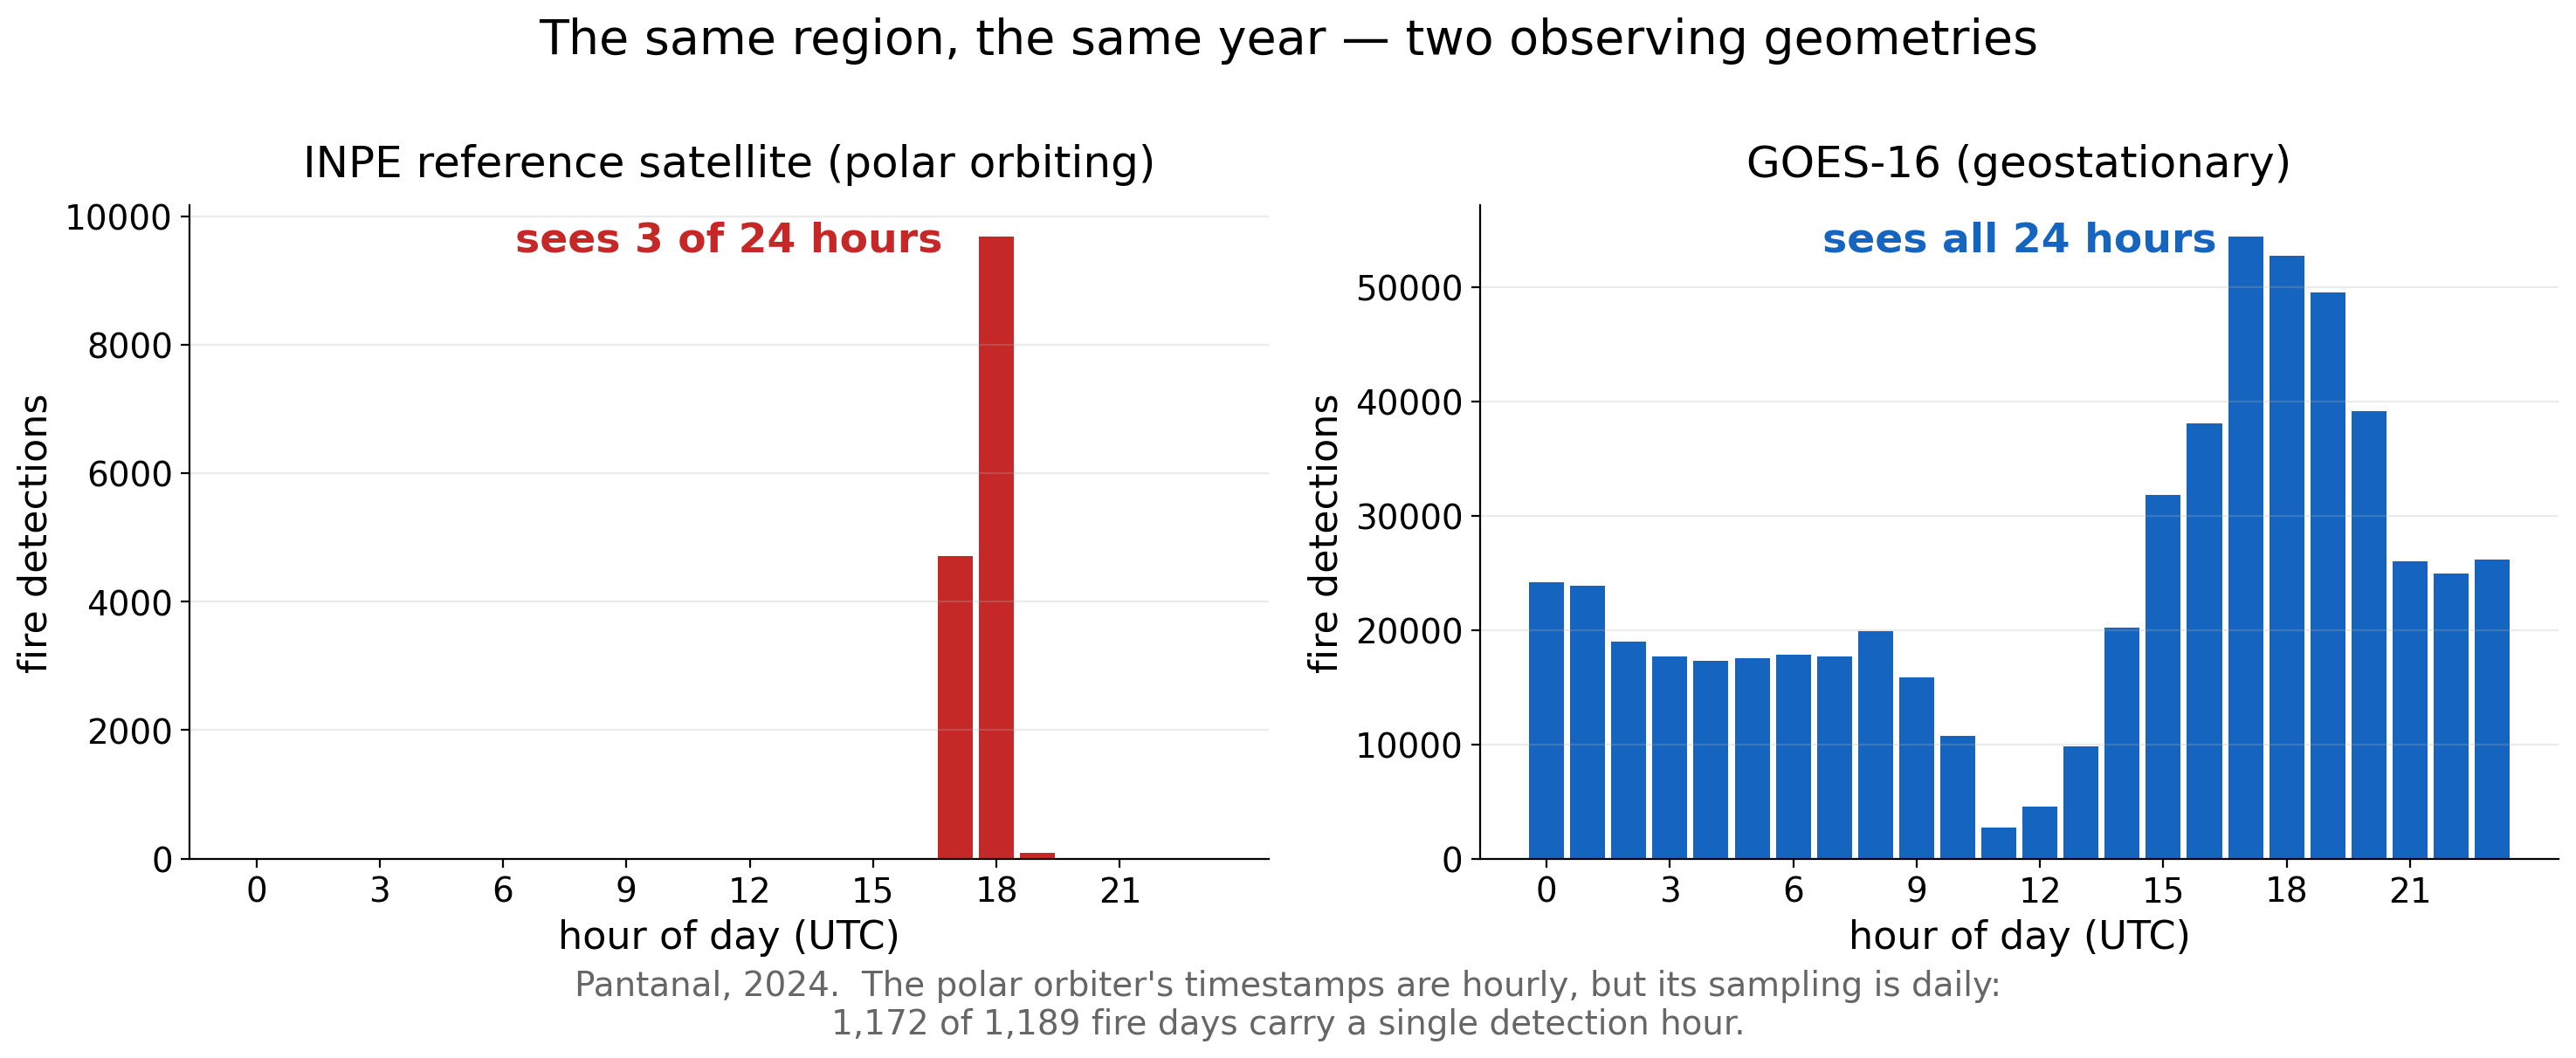

In [7]:
show_figure("fig1_observing_window.png")

### 3.2 ERA5 hourly weather

ERA5 is a **reanalysis**: millions of past observations combined with a weather model to reconstruct the atmosphere everywhere, every hour, on a 0.25° grid. The project downloaded four raw variables over the domain for 2019–2024 (`u10`, `v10`, `t2m`, `d2m`) and derived four more: wind speed, the direction the wind blows **to**, relative humidity and vapour pressure deficit (VPD). The file is opened lazily, so only the parts used are read from disk.

[live] dimensions: {'time': 52608, 'lat': 49, 'lon': 29}
       period    : 2019-01-01T00:00 -> 2024-12-31T23:00
       variables : ['u10', 'v10', 't2m', 'd2m', 'wind_speed', 'wind_dir_to_deg', 'rh', 'vpd']


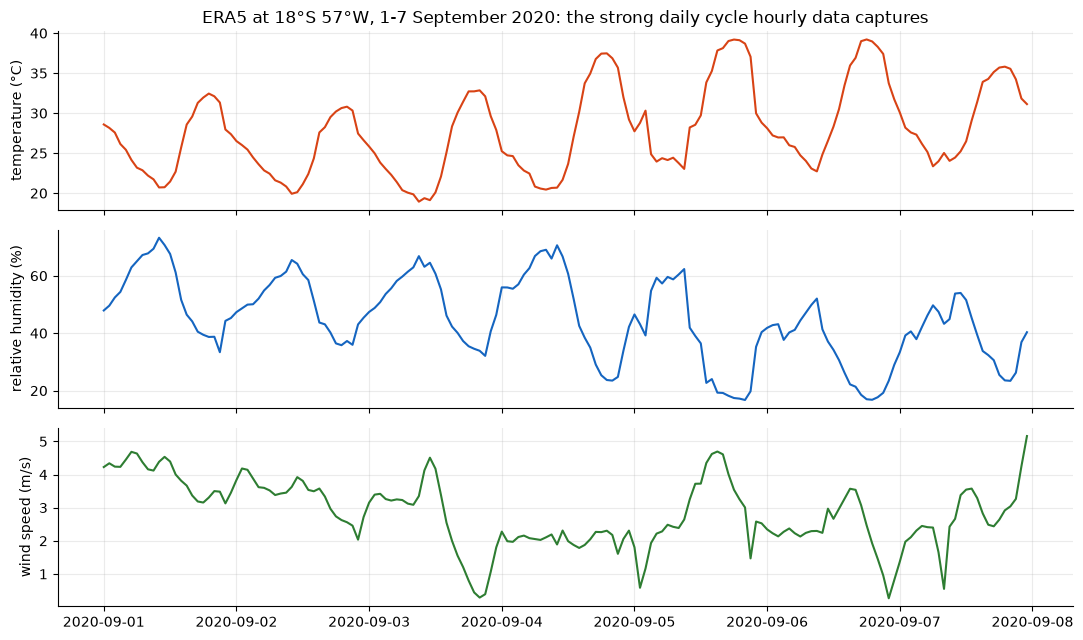

In [8]:
import xarray as xr

era5 = xr.open_dataset(HOURLY / "data" / "era5_hourly_2019_2024.nc")
print(f"[live] dimensions: {dict(era5.sizes)}")
print(f"       period    : {str(era5.time.values[0])[:16]} -> {str(era5.time.values[-1])[:16]}")
print(f"       variables : {list(era5.data_vars)}")

# one week at one point in the central Pantanal during the extreme 2020 season
pt = (era5.sel(lat=-18.0, lon=-57.0, method="nearest")
          .sel(time=slice("2020-09-01", "2020-09-07")).load())
fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
axes[0].plot(pt.time, pt.t2m - 273.15, color=FIRE_C); axes[0].set_ylabel("temperature (°C)")
axes[1].plot(pt.time, pt.rh, color=GOES_C); axes[1].set_ylabel("relative humidity (%)")
axes[2].plot(pt.time, pt.wind_speed, color=GOOD_C); axes[2].set_ylabel("wind speed (m/s)")
axes[0].set_title("ERA5 at 18°S 57°W, 1-7 September 2020: the strong daily cycle hourly data captures")
plt.tight_layout(); plt.show()

Afternoon temperatures near 40 °C with humidity below 20%, then cool, humid nights: a daily average would erase exactly this. That is the motivation for hourly weather features.

**How humidity and VPD are derived.** Relative humidity compares how much water vapour the air holds ($e_a$, from the dew point) with how much it could hold ($e_s$, from the temperature), using the Tetens formula $e = 6.1078\,\exp\!\big(17.27\,T/(T+237.3)\big)$ in hPa with $T$ in °C. Then $RH = 100\,e_a/e_s$ and $VPD = e_s - e_a$. VPD measures how strongly dry air pulls moisture out of vegetation, a standard fire-danger indicator. The cell below recomputes both from the raw variables and checks them against the stored values.

In [9]:
def sat_vp(t_c):
    return 6.1078 * np.exp(17.27 * t_c / (t_c + 237.3))   # hPa

t_c, td_c = pt.t2m - 273.15, pt.d2m - 273.15
es, ea = sat_vp(t_c), sat_vp(td_c)
rh_check = (100 * ea / es).clip(max=100)
vpd_check = (es - ea).clip(min=0)

wind_to = (np.degrees(np.arctan2(pt.u10, pt.v10)) + 360) % 360   # direction the wind blows TO
dir_err = np.abs(((wind_to - pt.wind_dir_to_deg) + 180) % 360 - 180)

print(f"[live] largest difference, recomputed vs stored: RH {float(np.abs(rh_check - pt.rh).max()):.4f} %, "
      f"VPD {float(np.abs(vpd_check - pt.vpd).max()):.4f} hPa, wind direction {float(dir_err.max()):.4f} degrees")

[live] largest difference, recomputed vs stored: RH 0.0000 %, VPD 0.0000 hPa, wind direction 0.0000 degrees


The stored wind direction is the direction the wind blows **to** (the direction a fire would be pushed), not the meteorological convention of where it comes **from**. Only this convention is stored, on purpose: keeping both around is how a sign gets flipped by accident (Section 4 shows a likely case in the daily model).

### 3.3 XHWI, blocking and SACZ

The laboratory's **XHWI** heatwave index exists only for 2024. Using it would have meant discarding five of the six years, so it was not used in the multi-year model; the raw quantities it is built from (temperature, humidity, VPD) were used instead, plus a count of hours above 32 °C that mimics its threshold. The code adds the XHWI block automatically if it ever covers every year.

The **atmospheric blocking** and **SACZ** (South Atlantic Convergence Zone) series are daily indices from the laboratory, covering 2019–2024, and were used as features in Stage 1. A 30-day precipitation index (SPI) also exists but stops on 2024-10-19, so it was left out.

In [10]:
xhwi = xr.open_dataset(PROJECT / "xhwi_era5_hourly_2024.nc")
print(f"[live] XHWI covers {str(xhwi.time.values[0])[:10]} -> {str(xhwi.time.values[-1])[:10]} "
      f"({xhwi.sizes['time']:,} hours) on the same 49 x 29 grid")

block = pd.read_csv(PROJECT / "serie_diaria_bloqueios_clima80_10.csv", parse_dates=["time"])
sacz = pd.read_csv(PROJECT / "SACZ_daily_series.csv", parse_dates=["time"])
for name, d in [("blocking", block), ("SACZ", sacz)]:
    print(f"[live] {name:8s}: {d.time.min().date()} -> {d.time.max().date()}, columns {list(d.columns[1:])}")

[live] XHWI covers 2024-01-01 -> 2024-12-31 (8,784 hours) on the same 49 x 29 grid
[live] blocking: 1960-01-01 -> 2025-12-31, columns ['total', 'norte', 'norte_h1', 'norte_h2', 'sul', 'sul_h1', 'sul_h2']
[live] SACZ    : 1961-01-01 -> 2025-12-31, columns ['SACZ_AB', 'SACZ_C', 'SACZ_DE']


### 3.4 GOES-16: what the fire product says, and where its pixels are

GOES-16 is a **geostationary** satellite: it sits 36,000 km above the equator and always looks at the same half of the planet, producing a fire map of the Americas every 10 minutes. Each ~2 km pixel gets a **mask code**. The project's `goes_grid.py` module turns those codes into three classes:

In [11]:
import goes_grid as gg

print("[live] mask codes, as defined in goes_grid.py")
print(f"  fire                 : {sorted(gg.FIRE_CODES_ALL)}")
print(f"  observed, no fire    : {gg.NO_FIRE_CODE}")
print("  not observed         : everything else (cloud, sun glint, off-disk, bad data: 40, 50, 60, 120+)")

demo = np.array([10, 30, 35, 100, 40, 50, 60, 120, 150])
fire, no_fire, unobs = gg.classify(demo)
display(pd.DataFrame({"mask code": demo, "fire": fire, "observed, no fire": no_fire, "not observed": unobs}))

[live] mask codes, as defined in goes_grid.py
  fire                 : [10, 11, 12, 13, 14, 15, 30, 31, 32, 33, 34, 35]
  observed, no fire    : 100
  not observed         : everything else (cloud, sun glint, off-disk, bad data: 40, 50, 60, 120+)


,mask code,fire,"observed, no fire",not observed
0,10,True,False,False
1,30,True,False,False
2,35,True,False,False
3,100,False,True,False
4,40,False,False,True
5,50,False,False,True
6,60,False,False,True
7,120,False,False,True
8,150,False,False,True


That third class is the key. A polar orbiter that sees no fire cannot say whether the fire went out or was hidden; GOES-16 says explicitly "I looked, and nothing was burning" (code 100). A **zero becomes an observation**. Cloudy cells are excluded rather than counted as fire-free: a 0.25° cell-hour is kept only if at least half of its pixels were observed.

**Locating the pixels.** GOES images are stored as scan angles seen from the satellite, not latitude and longitude. `goes_grid.py` implements the conversion in both directions from NOAA's published equations. A round trip should return the starting point exactly.

In [12]:
lon = np.array([-57.0, -60.0, -53.0, -55.5])
lat = np.array([-18.0, -25.0, -13.0, -20.1])
x, y = gg.lonlat_to_scan(lon, lat)          # degrees -> scan angles (radians)
lon2, lat2 = gg.scan_to_lonlat(x, y)        # and back
print(f"[live] largest round-trip error: {max(np.abs(lon2 - lon).max(), np.abs(lat2 - lat).max()):.1e} degrees")

grid = json.loads((GOES / "data" / "goes_pixel_grid.json").read_text())
print(f"[live] Pantanal window of the full disk: {grid['window_shape'][0]} x {grid['window_shape'][1]} pixels, "
      f"{grid['n_in_window']:,} of them inside the domain")

[live] largest round-trip error: 2.8e-13 degrees
[live] Pantanal window of the full disk: 615 x 420 pixels, 211,324 of them inside the domain


Reading only this window instead of decoding the whole disk (Alaska to Patagonia) made each file 40 times faster to process: 83 ms instead of 3.3 s, with identical output.

## 4. Stage 0: auditing the laboratory's daily model

The daily model reports a persistence ROC-AUC of about **0.93**. Before building anything new, it was worth understanding where that score came from. The daily table is `tabela_ml_wind.parquet` (column names in Portuguese: `persiste_t1` = persists next day, `persistencia_acumulada` = days already burning).

In [13]:
daily = pd.read_parquet(PROJECT / "tabela_ml_wind.parquet")
dp = daily[daily.bioma == "Pantanal"]
rows_per_event = dp.groupby("evento_id").size()
print(f"[live] Pantanal events in the daily table: {len(rows_per_event):,}; "
      f"events with a single day: {(rows_per_event == 1).sum()}")

[live] Pantanal events in the daily table: 7,311; events with a single day: 34


Almost every event in the daily table lasts **at least two days**: the table was built that way. So on the first day of any event, a second day exists *by construction*. That means the column "days already burning = 0" gives the answer away. The test below uses the daily model's own saved test predictions (2023–2024).

In [14]:
from sklearn.metrics import f1_score

pred = pd.read_csv(PROJECT / "results" / "pantanal_only" / "predicoes_finais_teste_wind.csv")
q = pred[(pred.target == "persiste_t1") & (pred.model == "XGBoost") & (pred.feature_set == "baseline")]
rule = (q.persistencia_acumulada == 0).astype(int)      # "first day -> it will persist"

print(f"[live] test rows: {len(q):,}; rows on an event's first day: {rule.sum():,}, "
      f"of which persisted: {q.y_true[rule == 1].mean():.0%}\n")
cmp_daily = pd.DataFrame({
    "accuracy": [accuracy_score(q.y_true, rule), accuracy_score(q.y_true, q.y_pred)],
    "F1 (macro)": [f1_score(q.y_true, rule, average="macro"), f1_score(q.y_true, q.y_pred, average="macro")],
    "ROC-AUC": [roc_auc_score(q.y_true, rule), roc_auc_score(q.y_true, q.y_score)],
}, index=["one-line rule, no model", "tuned XGBoost"])
display(cmp_daily)

[live] test rows: 2,692; rows on an event's first day: 1,204, of which persisted: 100%



,accuracy,F1 (macro),ROC-AUC
"one-line rule, no model",0.8956,0.8956,0.9054
tuned XGBoost,0.8952,0.8952,0.9321


A one-line rule with no model at all scores almost as well as the tuned XGBoost (the model adds about +0.03 ROC-AUC and nothing on F1). The daily persistence score mostly reflects **how the table was filtered**, not predictive skill. This is not a coding mistake; it is a sampling artefact: membership in the table is itself informative about the answer.

Two more observations on the daily model:

- **Its wind direction convention.** The predominant wind direction it uses points mostly north and north-east over the Pantanal, which matches the *meteorological* convention (where the wind comes **from**). Its documentation treats it as the direction of travel, which would invert the meaning of its wind–fire alignment feature. Confirming this needs the code that produced the column, which is not in this folder.
- **Unseeded tuning.** Its hyperparameter search (Optuna) had no seed, so re-running it gives different numbers (Section 5.7 shows how large that effect is).

In [15]:
print("[live] predominant wind direction label, Pantanal rows of the daily table:")
display(dp.wind_dir_predominant_label.value_counts(normalize=True).head(4).rename("share").to_frame())

daily_metrics = pd.read_csv(PROJECT / "results" / "pantanal_only" / "metricas_finais_teste_wind.csv")
full = daily_metrics[daily_metrics.period.str.contains("full")]
print("[saved] daily model, test 2023-2024:")
display(full.pivot_table(index=["target", "model"], columns="feature_set",
                         values=["roc_auc", "pr_auc"]).round(3))

[live] predominant wind direction label, Pantanal rows of the daily table:


,share
wind_dir_predominant_label,
N,0.3253
NE,0.3033
S,0.1240
E,0.0920


[saved] daily model, test 2023-2024:


pr_auc            roc_auc          
feature_set              baseline with_wind baseline with_wind
target      model                                             
persiste_t1 RandomForest   0.9610    0.9610   0.9320    0.9330
            XGBoost        0.9610    0.9610   0.9320    0.9340
propaga_t1  RandomForest   0.4440    0.4590   0.6840    0.7040
            XGBoost        0.4690    0.4560   0.7090    0.7100

## 5. Stage 1: the INPE-based model with hourly weather (2019–2024)

Because INPE sees the Pantanal once a day, this model has a **daily target** (what happens at the next overpass, about 24 h later) but **hourly weather**: conditions at the exact time of detection and over the preceding 24 h, instead of daily averages.

### 5.1 From detections to fire events

**Clustering.** Nearby detections from the same overpass usually belong to the same fire. They are grouped with **DBSCAN**, which links points closer than a chosen distance. A distance of 1.4 km reproduced the laboratory's original grouping almost exactly (agreement score ARI = 0.974, where 1 means identical), and the same rule was then applied to every year. The cell below re-runs it on the busiest Pantanal overpass of 2020 and checks it against the stored clusters.

[live] overpass 2020-09-12 17:00:00: 1,093 Pantanal detections -> 355 fire clusters
[live] agreement with the stored clusters for this overpass (ARI): 1.000


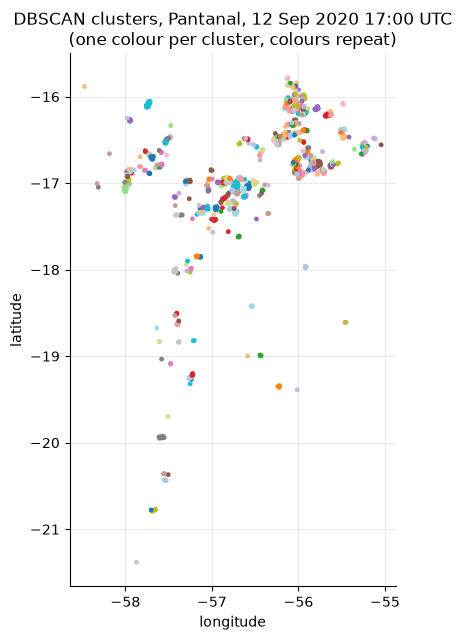

In [16]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score

EARTH_KM = 6371.0088
busiest = pant[pant.detection_hour.dt.year == 2020].detection_hour.value_counts().idxmax()
regional_pass = inpe[inpe.detection_hour == busiest]          # clustering runs on all of MT + MS
labels = DBSCAN(eps=1.4 / EARTH_KM, min_samples=1, metric="haversine",
                algorithm="ball_tree").fit_predict(np.radians(regional_pass[["lat", "lon"]]))
ari = adjusted_rand_score(regional_pass.event_id, labels)
one = regional_pass.assign(cluster=labels)[regional_pass.biome == "Pantanal"]

print(f"[live] overpass {busiest}: {len(one):,} Pantanal detections -> {one.cluster.nunique():,} fire clusters")
print(f"[live] agreement with the stored clusters for this overpass (ARI): {ari:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(one.lon, one.lat, c=one.cluster % 20, cmap="tab20", s=6)
ax.set(title=f"DBSCAN clusters, Pantanal, {busiest:%d %b %Y %H:%M} UTC\n(one colour per cluster, colours repeat)",
       xlabel="longitude", ylabel="latitude", aspect="equal")
plt.tight_layout(); plt.show()

**Following fires through time.** A cluster is linked to one seen at the next overpass if they are within **5 km**. Linked clusters form a *chain*: one fire followed day after day. Two targets are then defined:

- `persists_t1` = 1 if some cluster is detected within 5 km at the next overpass;
- `spreads_t1` = 1 if a **new** cluster (one that starts its own chain) appears in the ring between 5 and 20 km.

**Was the next day observed?** If nothing is detected the next day, either the fire went out or the satellite did not pass. Detections anywhere in MT + MS are used as proof that the satellite did pass. Clusters whose next day was not observed are **removed**, never labelled "extinguished". This is why the detections are kept for both whole states: filtering to the Pantanal *first* removed exactly that evidence, and wrongly dropped 433 clusters instead of 76.

### 5.2 The modelling table

In [17]:
inpe_tab = pd.read_parquet(HOURLY / "data" / "hourly_ml_table_pantanal.parquet").sort_values("detection_hour")
print(f"[live] {len(inpe_tab):,} fire clusters (rows) x {inpe_tab.shape[1]} columns\n")
per_year = inpe_tab.groupby("year").agg(clusters=("event_id", "size"),
                                        share_persisting=("persists_t1", "mean"),
                                        share_spreading=("spreads_t1", "mean"))
display(per_year)

[live] 26,951 fire clusters (rows) x 108 columns



,clusters,share_persisting,share_spreading
year,,,
2019,4695,0.2999,0.2571
2020,9851,0.4295,0.3239
2021,3563,0.3348,0.2237
2022,845,0.2296,0.0817
2023,2427,0.3432,0.2546
2024,5570,0.4224,0.2858


The years are very uneven: 2020 was catastrophic and 2022 barely burned, and both target rates follow how severe the season was. A first version built on 2024 alone scored **at chance** (ROC-AUC 0.48–0.53): one year contains no information about year-to-year differences. Six years are what made the model work at all.

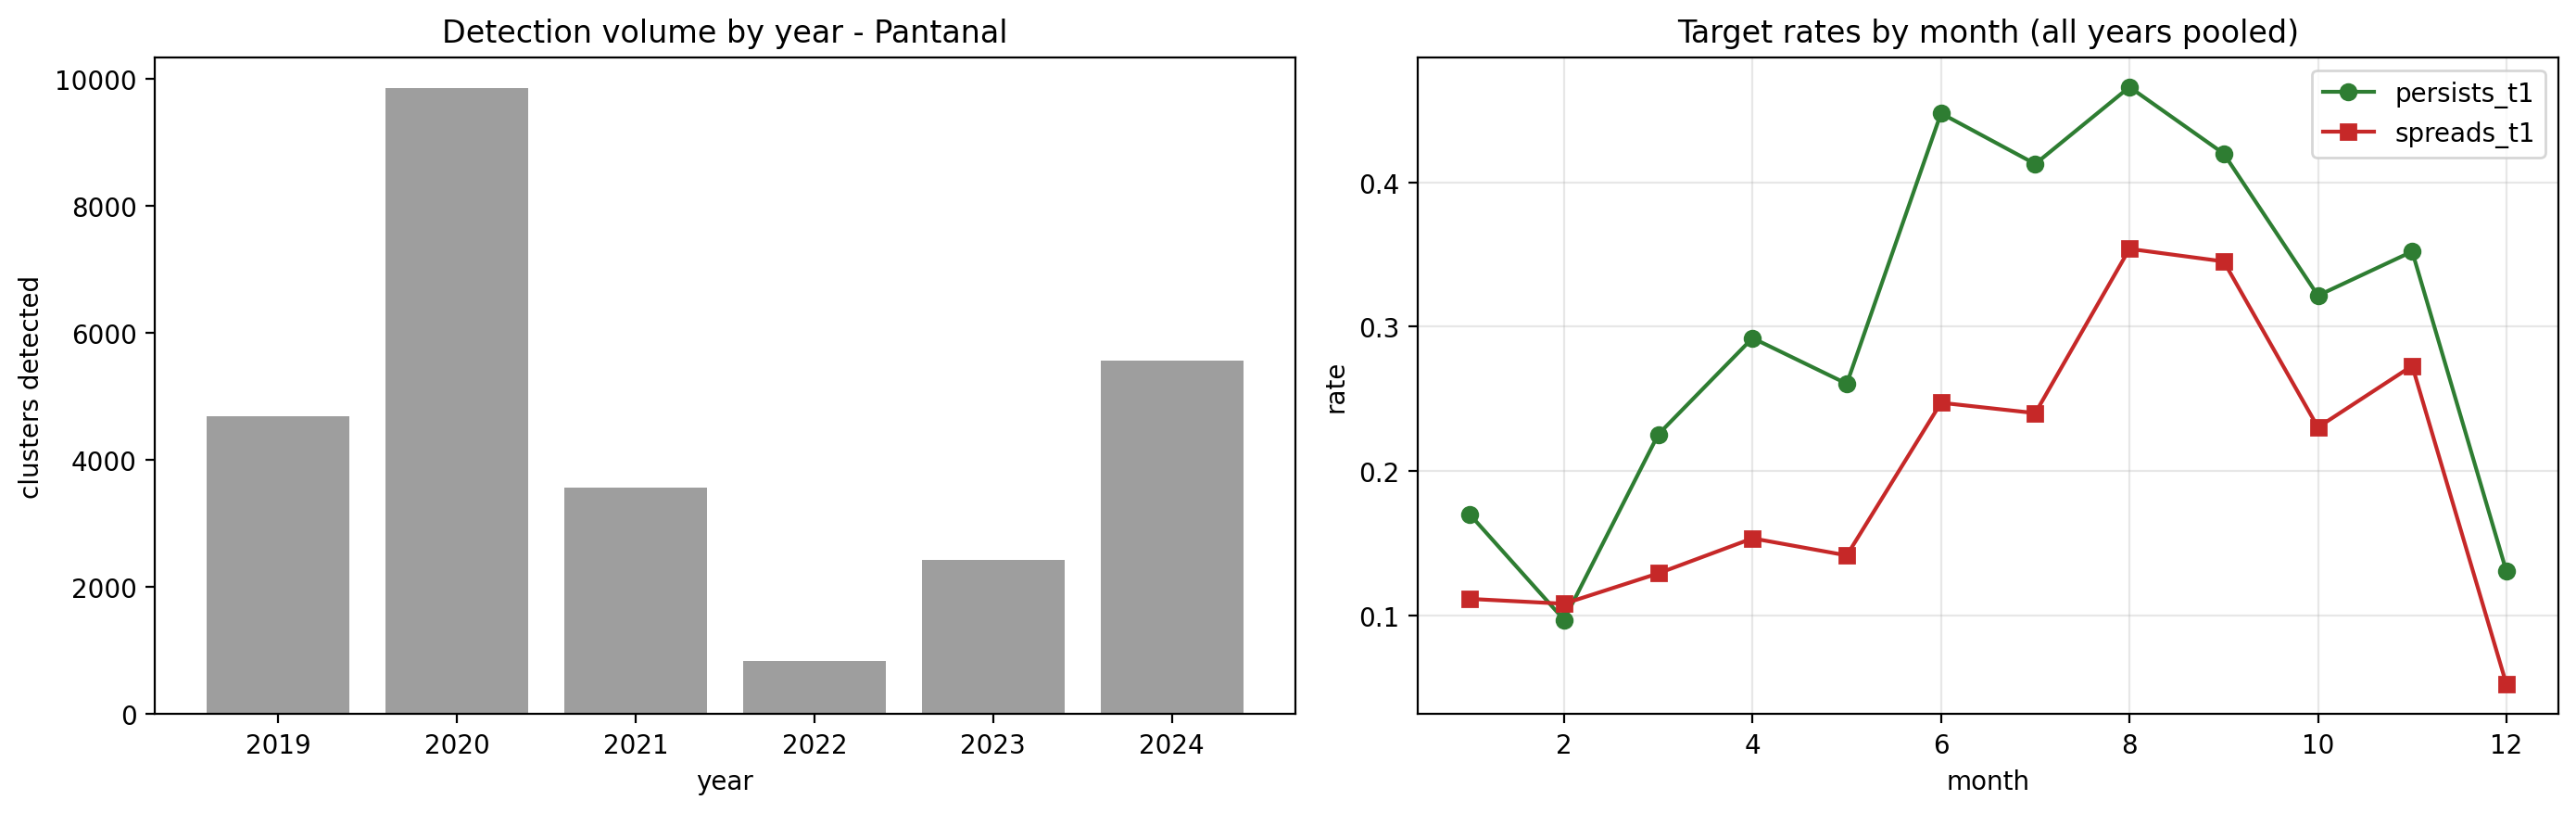

In [18]:
show_figure("fig_inpe_overview.png")

### 5.3 Features

The inputs are organised in **blocks**, so each block's contribution can be tested separately. The lists are imported from `hourly_model/feature_set_effect_size.py`.

- **Baseline**: what the daily model could see: position, number of detections, days already burning, season, year, *daily* ERA5 averages and maxima, blocking and SACZ.
- **Hourly thermal**: temperature, humidity and VPD at detection time and 1–12 h before, 24 h minimum/maximum/mean, hours above 32 °C, hours with humidity below 30%.
- **Geometry**: the shape of the cluster, distance to the nearest other fire, number of fires in the ring, movement since the last overpass.
- **Hourly wind**: speed, components and direction, their variability, and the alignment between wind and fire movement.
- **Timing** (tested, then dropped, see 5.6): the hour of detection and the time until the next overpass.

In [19]:
import feature_set_effect_size as fse

blocks = {"baseline": fse.BASELINE, "hourly thermal": fse.THERMAL, "geometry": fse.GEOMETRY,
          "hourly wind": fse.WIND, "timing (dropped)": fse.TIMING}
display(pd.DataFrame({"features": [len(v) for v in blocks.values()],
                      "examples": [", ".join(v[:5]) + (", ..." if len(v) > 5 else "") for v in blocks.values()]},
                     index=list(blocks)))
print("Feature sets compared (each adds a block to the previous one):")
for name, feats in fse.FEATURE_SETS.items():
    print(f"  {name:26s} {len(feats):3d} features")

,features,examples
baseline,27,"lat, lon, n_hotspots, persistence_accumulated,..."
hourly thermal,26,"t2m_t, t2m_lag1, t2m_lag3, t2m_lag6, t2m_lag12..."
geometry,11,"cluster_spread_km, cluster_radius_km, cluster_..."
hourly wind,13,"wind_speed_t, wind_speed_lag3, wind_speed_lag6..."
timing (dropped),2,"dt_next_overpass_h, detection_hour_utc"


Feature sets compared (each adds a block to the previous one):
  baseline                    27 features
  with_hourly                 64 features
  with_hourly_wind            77 features
  with_hourly_wind_timing     79 features


### 5.4 Train and test split

The model is trained on **2019–2022** and tested on **2023–2024**. The test years come strictly after the training years, as they would in real use. Chains that cross from 2022 into 2023 are removed from training, so the same fire never appears on both sides.

In [20]:
test_chains = set(inpe_tab.loc[inpe_tab.year > fse.YEAR_TRAIN_END, "chain_id"])
inpe_tr = inpe_tab[(inpe_tab.year <= fse.YEAR_TRAIN_END) & ~inpe_tab.chain_id.isin(test_chains)]
inpe_te = inpe_tab[inpe_tab.year > fse.YEAR_TRAIN_END]
print(f"[live] train 2019-2022: {len(inpe_tr):,} clusters | test 2023-2024: {len(inpe_te):,} clusters")
print(f"       test base rates: persistence {inpe_te.persists_t1.mean():.3f}, spread {inpe_te.spreads_t1.mean():.3f}")

[live] train 2019-2022: 18,954 clusters | test 2023-2024: 7,997 clusters
       test base rates: persistence 0.398, spread 0.276


### 5.5 Training one model, step by step

Here is what "training a model" means in practice: XGBoost (hundreds of small decision trees, each correcting the previous ones) learns from the 2019–2022 rows, then outputs a probability of persistence for every 2023–2024 cluster it has never seen. The settings are the project's fixed configuration: 400 trees, depth 5, learning rate 0.05.

[live] persistence, test 2023-2024: ROC-AUC 0.643 (coin flip = 0.5), PR-AUC 0.528 (no skill = 0.398)

At a 50% threshold: precision 0.53 (share of 'yes' that were right), recall 0.42 (share of persisting fires caught)


,predicted: no,predicted: yes
did not persist,3622,1189
persisted,1841,1345


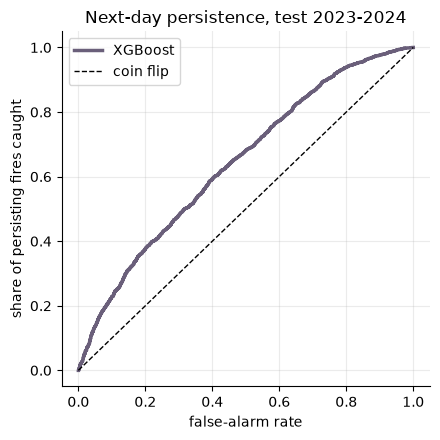

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from xgboost import XGBClassifier

feats = fse.FEATURE_SETS["with_hourly_wind"]
scaler = StandardScaler().fit(inpe_tr[feats])
model = XGBClassifier(**fse.FIXED, random_state=0).fit(scaler.transform(inpe_tr[feats]), inpe_tr.persists_t1)
p_test = model.predict_proba(scaler.transform(inpe_te[feats]))[:, 1]
y_test = inpe_te.persists_t1.values

print(f"[live] persistence, test 2023-2024: ROC-AUC {roc_auc_score(y_test, p_test):.3f} "
      f"(coin flip = 0.5), PR-AUC {average_precision_score(y_test, p_test):.3f} (no skill = {y_test.mean():.3f})")

alarm = (p_test >= 0.5).astype(int)
cm = pd.DataFrame(confusion_matrix(y_test, alarm),
                  index=["did not persist", "persisted"], columns=["predicted: no", "predicted: yes"])
print(f"\nAt a 50% threshold: precision {precision_score(y_test, alarm):.2f} "
      f"(share of 'yes' that were right), recall {recall_score(y_test, alarm):.2f} (share of persisting fires caught)")
display(cm)

fpr, tpr, _ = roc_curve(y_test, p_test)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(fpr, tpr, color=INPE_C, lw=2.5, label="XGBoost")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="coin flip")
ax.set(title="Next-day persistence, test 2023-2024", xlabel="false-alarm rate", ylabel="share of persisting fires caught")
ax.legend(); plt.tight_layout(); plt.show()

### 5.6 The noise floor, and why one run proves nothing

Training the *same* model with five different seeds gives five different scores. That spread is the noise floor: any difference between feature sets smaller than this is not evidence of anything.

This mattered in practice. Re-running an **identical** tuned configuration once moved persistence ROC-AUC from 0.631 to 0.601, as large as the differences being compared. The cause was that Optuna's search was not seeded (the estimator was, the search was not). Every study is now seeded, and feature sets are compared with fixed settings over several seeds, so differences come from the features and not from tuning luck.

In [22]:
seed_scores = []
for seed in range(N_SEEDS):
    m = XGBClassifier(**fse.FIXED, random_state=seed).fit(scaler.transform(inpe_tr[feats]), inpe_tr.persists_t1)
    seed_scores.append(roc_auc_score(y_test, m.predict_proba(scaler.transform(inpe_te[feats]))[:, 1]))
print(f"[live] same model, same data, {N_SEEDS} seeds: ROC-AUC " + ", ".join(f"{s:.4f}" for s in seed_scores))
print(f"       spread across seeds (std): {np.std(seed_scores, ddof=1):.4f}")

[live] same model, same data, 5 seeds: ROC-AUC 0.6427, 0.6486, 0.6526, 0.6487, 0.6436
       spread across seeds (std): 0.0041


### 5.7 Which feature blocks really help? (effect-size test)

Each feature set is trained with the same fixed settings over 5 seeds; the gain over the baseline is divided by the seed noise (σ). This is cheap enough to run live (about a minute), and the cell checks that it reproduces the saved results exactly.

The two targets are scored differently. Persistence (base rate 40%) uses ROC-AUC. Spread is rarer (28%), so it uses PR-AUC, and the model is told to weigh positive cases more (`scale_pos_weight`).

In [23]:
def effect_size_runs(tr, te, target, sets, seeds, fixed, scale_pos_weight=1.0):
    # identical fixed hyperparameters for every feature set, repeated over seeds
    rows = []
    for name, cols in sets.items():
        sc = StandardScaler().fit(tr[cols])
        Xtr, Xte = sc.transform(tr[cols]), sc.transform(te[cols])
        for seed in range(seeds):
            m = XGBClassifier(**fixed, scale_pos_weight=scale_pos_weight, random_state=seed).fit(Xtr, tr[target])
            s = m.predict_proba(Xte)[:, 1]
            rows.append({"feature_set": name, "seed": seed,
                         "roc_auc": roc_auc_score(te[target], s), "pr_auc": average_precision_score(te[target], s)})
    return pd.DataFrame(rows)


def summarise(runs, metric, reference, order):
    # mean, seed noise, gain over the reference set, and gain in units of noise
    g = runs.groupby("feature_set")[metric]
    mean, std = g.mean(), g.std()
    noise = std.max()
    out = pd.DataFrame({"mean": mean, "std across seeds": std, "gain": mean - mean[reference]})
    out["gain / noise (sigma)"] = out["gain"] / noise
    return out.loc[order]


t0 = time.time()
inpe_runs = []
for target in ["persists_t1", "spreads_t1"]:
    spw = (inpe_tr[target] == 0).sum() / (inpe_tr[target] == 1).sum() if target == "spreads_t1" else 1.0
    inpe_runs.append(effect_size_runs(inpe_tr, inpe_te, target, fse.FEATURE_SETS, N_SEEDS, fse.FIXED, spw)
                     .assign(target=target))
inpe_runs = pd.concat(inpe_runs, ignore_index=True)
print(f"[live] trained {len(inpe_runs)} models in {time.time() - t0:.0f} s")

saved = pd.read_csv(HOURLY / "results" / "feature_set_effect_size_raw.csv")
merged = inpe_runs.merge(saved, on=["target", "feature_set", "seed"], suffixes=("", "_saved"))
print(f"[check] largest difference from the saved results: "
      f"{max((merged.roc_auc - merged.roc_auc_saved).abs().max(), (merged.pr_auc - merged.pr_auc_saved).abs().max()):.1e}")

order = list(fse.FEATURE_SETS)
print("\nPersistence (ROC-AUC):")
display(summarise(inpe_runs[inpe_runs.target == "persists_t1"], "roc_auc", "baseline", order))
print("Spread (PR-AUC, base rate {:.3f}):".format(inpe_te.spreads_t1.mean()))
display(summarise(inpe_runs[inpe_runs.target == "spreads_t1"], "pr_auc", "baseline", order))

[live] trained 40 models in 135 s
[check] largest difference from the saved results: 5.6e-17

Persistence (ROC-AUC):


,mean,std across seeds,gain,gain / noise (sigma)
feature_set,,,,
baseline,0.6208,0.0078,0.0000,0.0000
with_hourly,0.6333,0.0056,0.0125,1.6034
with_hourly_wind,0.6472,0.0041,0.0265,3.3867
with_hourly_wind_timing,0.6436,0.0033,0.0228,2.9182


Spread (PR-AUC, base rate 0.276):


,mean,std across seeds,gain,gain / noise (sigma)
feature_set,,,,
baseline,0.3554,0.0045,0.0000,0.0000
with_hourly,0.3443,0.0077,-0.0111,-0.9825
with_hourly_wind,0.3615,0.0113,0.0061,0.5397
with_hourly_wind_timing,0.3358,0.0096,-0.0197,-1.7371


**Reading the tables:**

- **Persistence:** hourly weather gives a real gain, +0.027 ROC-AUC at 3.4σ, mostly thanks to **hourly wind** (the hourly thermal and geometry block alone is only 1.6σ, borderline).
- **Spread:** no block gives an effect distinguishable from noise; everything lands within about ±1.7σ.
- **Timing features:** adding them back makes *both* targets worse. They ranked near the top of XGBoost's feature importance, yet removing them improved the model. **Feature importance counts how often a feature was used, not whether it helped.** The only reliable test is the one above: train with and without, and compare against the noise.

An earlier ablation (removing whole blocks) also found that **cluster geometry** is the strongest block (persistence fell from 0.636 to 0.600 without it), and that among weather variables **relative humidity** carries the most information. A temperature-threshold index such as XHWI would have partly hidden that humidity signal.

### 5.8 Tuned models [saved]

Separately, each feature set was tuned with Optuna (seeded) for XGBoost and random forest. These are the headline numbers:

In [24]:
tuned_inpe = pd.read_csv(HOURLY / "results" / "final_test_metrics_hourly.csv")
tuned_inpe = tuned_inpe[tuned_inpe.period == "test_full"]
order_sets = ["baseline", "with_hourly", "with_hourly_wind"]
for target, metric in [("persists_t1", "roc_auc"), ("spreads_t1", "pr_auc")]:
    t = tuned_inpe[tuned_inpe.target == target].pivot(index="model", columns="feature_set", values=metric)
    print(f"[saved] {target} ({metric}), test 2023-2024:")
    display(t[[c for c in order_sets if c in t.columns]].round(3))
best_spread = tuned_inpe[(tuned_inpe.target == "spreads_t1") & (tuned_inpe.model == "XGBoost")
                         & (tuned_inpe.feature_set == "with_hourly_wind")].iloc[0]
print(f"Best spread model: ROC-AUC {best_spread.roc_auc:.3f}, lift {best_spread.pr_auc / best_spread.prevalence_positive:.2f}x")

[saved] persists_t1 (roc_auc), test 2023-2024:


feature_set,baseline,with_hourly,with_hourly_wind
model,,,
RandomForest,0.6060,0.6560,0.6560
XGBoost,0.6320,0.6590,0.6700


[saved] spreads_t1 (pr_auc), test 2023-2024:


feature_set,baseline,with_hourly,with_hourly_wind
model,,,
RandomForest,0.3250,0.3450,0.3640
XGBoost,0.3670,0.3850,0.3890


Best spread model: ROC-AUC 0.652, lift 1.41x


### 5.9 Two leaks found and fixed

**Leakage** is information about the answer hidden in the inputs. It is the most dangerous error in applied machine learning because it *improves* the scores.

1. **Time to the next overpass.** It was first computed from Pantanal detections, so it was undefined on days nothing burned and filled with 24 h. The filled value itself revealed that the fire had not persisted (persistence 0.218 at the filled value against 0.477 elsewhere). It was recomputed from regional overpass times, which exist whatever burns, and later dropped altogether.
2. **Heatwave "hours since peak".** With an all-zero 24 h window (over half the rows), the code reported "peak 23 h ago" instead of "no peak". Those rows now get −1.

### 5.10 Comparing with the daily model fairly

The same one-line rule from Section 4 ("first day → it persists") can be tried on this table, which has no two-day filter:

In [25]:
rule_h = (inpe_te.persistence_accumulated == 0).astype(int)
print(f"[live] on the hourly-forcing test set, 'first day' rows persist only {inpe_te.persists_t1[rule_h == 1].mean():.1%} of the time")
print(f"       one-line rule F1 (macro): {f1_score(inpe_te.persists_t1, rule_h, average='macro'):.3f}  "
      f"vs daily table: {f1_score(q.y_true, rule, average='macro'):.3f}")

[live] on the hourly-forcing test set, 'first day' rows persist only 32.5% of the time
       one-line rule F1 (macro): 0.400  vs daily table: 0.896


| | Daily model | Hourly-forcing model |
|---|---|---|
| Question actually answered | "given this fire lasts ≥ 2 days, is today day one?" | "will this fire still be here tomorrow?" |
| One-line rule, F1 | 0.896 | 0.400 |
| Model, F1 | 0.895 | 0.604 |
| Gain of the model over the rule | ≈ 0 | +0.20 |
| Spread: base rate → best PR-AUC (lift) | 0.292 → 0.469 (1.61×) | 0.276 → 0.389 (1.41×) |

The hourly-forcing model scores lower on a harder, unfiltered and more useful question: in real use, nobody knows in advance which fires will last two days. For **spread**, where no artefact exists, the daily model is genuinely ahead, though on a smaller and more selected test set.

## 6. Stage 2: a truly hourly target with GOES-16 (2024)

### 6.1 Why INPE cannot give an hourly target

One could try to make an hourly target from INPE by treating every hour without a detection as "no fire" (*zero-fill*). The cell below builds that table for 2024 on the 0.25° grid and asks how well **the hour of day alone** predicts "fire". The "model" is just the fire rate of each hour, learned on January–August and tested on September–December.

In [26]:
p24 = pant[pant.detection_hour.dt.year == 2024].copy()
p24["cell"] = (np.floor((p24.lat + 25) / 0.25 + 0.5).astype(int) * 29
               + np.floor((p24.lon + 60) / 0.25 + 0.5).astype(int))
cells = p24.cell.nunique()                                    # cells where the Pantanal burned in 2024
fire_ch = p24.drop_duplicates(["cell", "detection_hour"])
hours = pd.Series(pd.date_range("2024-01-01", "2024-12-31 23:00", freq="h"))

def counts(mask_hours, mask_fire):
    # fire and no-fire cell-hours per hour of day
    pos = np.bincount(fire_ch.detection_hour[mask_fire].dt.hour, minlength=24)
    total = np.bincount(hours[mask_hours].dt.hour, minlength=24) * cells
    return pos, total - pos

train_pos, train_neg = counts(hours.dt.month <= 8, fire_ch.detection_hour.dt.month <= 8)
test_pos, test_neg = counts(hours.dt.month > 8, fire_ch.detection_hour.dt.month > 8)
rate = train_pos / (train_pos + train_neg)                    # the "model": fire rate by hour

# score every test cell-hour by its hour's training rate (grouped with weights for speed)
y_g = np.r_[np.ones(24), np.zeros(24)]
s_g = np.r_[rate, rate]
w_g = np.r_[test_pos, test_neg]
print(f"[live] zero-fill table: base rate {test_pos.sum() / w_g.sum():.5f} "
      f"(about {test_pos.sum() / w_g.sum() * 1e4:.0f} fire cell-hours in 10,000)")
print(f"[live] ROC-AUC of 'hour of day' alone on Sep-Dec: {roc_auc_score(y_g, s_g, sample_weight=w_g):.3f}")

[live] zero-fill table: base rate 0.00135 (about 14 fire cell-hours in 10,000)
[live] ROC-AUC of 'hour of day' alone on Sep-Dec: 0.965


The hour of day alone scores above 0.9, simply because INPE detections only exist in the hours the satellite passes. (The original analysis, on a slightly different cell set, measured base rate 0.000886 and ROC-AUC 0.917; the point is the same.) A model trained on such a table would learn the **satellite's orbit**, not fire behaviour. A satellite that actually looks every hour was needed: GOES-16.

### 6.2 Validating GOES-16 against INPE (August 2024)

Before trusting GOES-16, one month was checked in detail. August 2024 has all 744 hours.

In [27]:
aug = pd.read_parquet(GOES / "data" / "goes_hourly_pantanal_202408.parquet")
kept = aug[aug.obs_frac >= 0.5]
print(f"[live] August 2024: {aug.time.nunique()} hours, {len(kept):,} observed cell-hours, "
      f"{kept.fire_t.mean():.2%} with fire")
print(f"[live] coverage: median observed fraction {aug.obs_frac.median():.3f}; "
      f"{(aug.obs_frac >= 0.9).mean():.1%} of cell-hours had at least 90% of pixels observed")

match = pd.read_csv(GOES / "results" / "goes_vs_inpe_match_202408.csv", parse_dates=["hour"])
hit = match.both.sum() / match.inpe_cells.sum()
chance_all = kept.groupby("time").fire_t.mean().mean()          # all hours of the month
chance_same = (kept[kept.time.isin(match.hour)].groupby("time").fire_t.mean()
               .reindex(match.hour).mul(match.inpe_cells.values).sum() / match.inpe_cells.sum())
print(f"\n[saved] cell-hours where INPE saw fire: {match.inpe_cells.sum()}; GOES also saw fire in {match.both.sum()} ({hit:.1%})")
print(f"[live]  chance agreement, averaged over all hours of August : {chance_all:.1%} -> {hit / chance_all:.0f}x better")
print(f"[live]  chance agreement, at the same afternoon hours as INPE: {chance_same:.1%} -> {hit / chance_same:.1f}x better")

[live] August 2024: 744 hours, 919,743 observed cell-hours, 3.99% with fire


[live] coverage: median observed fraction 1.000; 90.8% of cell-hours had at least 90% of pixels observed

[saved] cell-hours where INPE saw fire: 517; GOES also saw fire in 403 (77.9%)
[live]  chance agreement, averaged over all hours of August : 3.8% -> 20x better
[live]  chance agreement, at the same afternoon hours as INPE: 10.1% -> 7.7x better


GOES-16 agrees with INPE about 78% of the time. What "chance" means matters here. The validation script compared against the fire rate averaged over all hours of the month (about 4%), which gives about 20×. But INPE passes in the afternoon, when far more cells are burning, so the fair baseline is the fire rate at those same hours (about 10%): GOES is then about **8 times better than chance**. That is still a strong validation, and the more honest number to quote. Perfect agreement is not expected: the instruments have different resolutions and sensitivities, and INPE's ~1 km sensor catches small fires a 2 km pixel can miss.

### 6.3 What GOES-16 reveals: the daily fire cycle

With an hourly view, a strong **daily cycle** appears that INPE cannot see. The 28 km model table (one row per burning cell-hour in 2024) shows it directly.

[saved] August: share of cell-hours burning peaks at 9.00% (14:00 local) and bottoms at 1.16% (06:00), a factor of 7.8
[live]  2024: 11.3% of fire activity happens between 00:00 and 06:00 local time
[live]  2024: chance a burning cell is still burning 1 h later peaks at 0.79 (09:00) and bottoms at 0.59 (13:00)


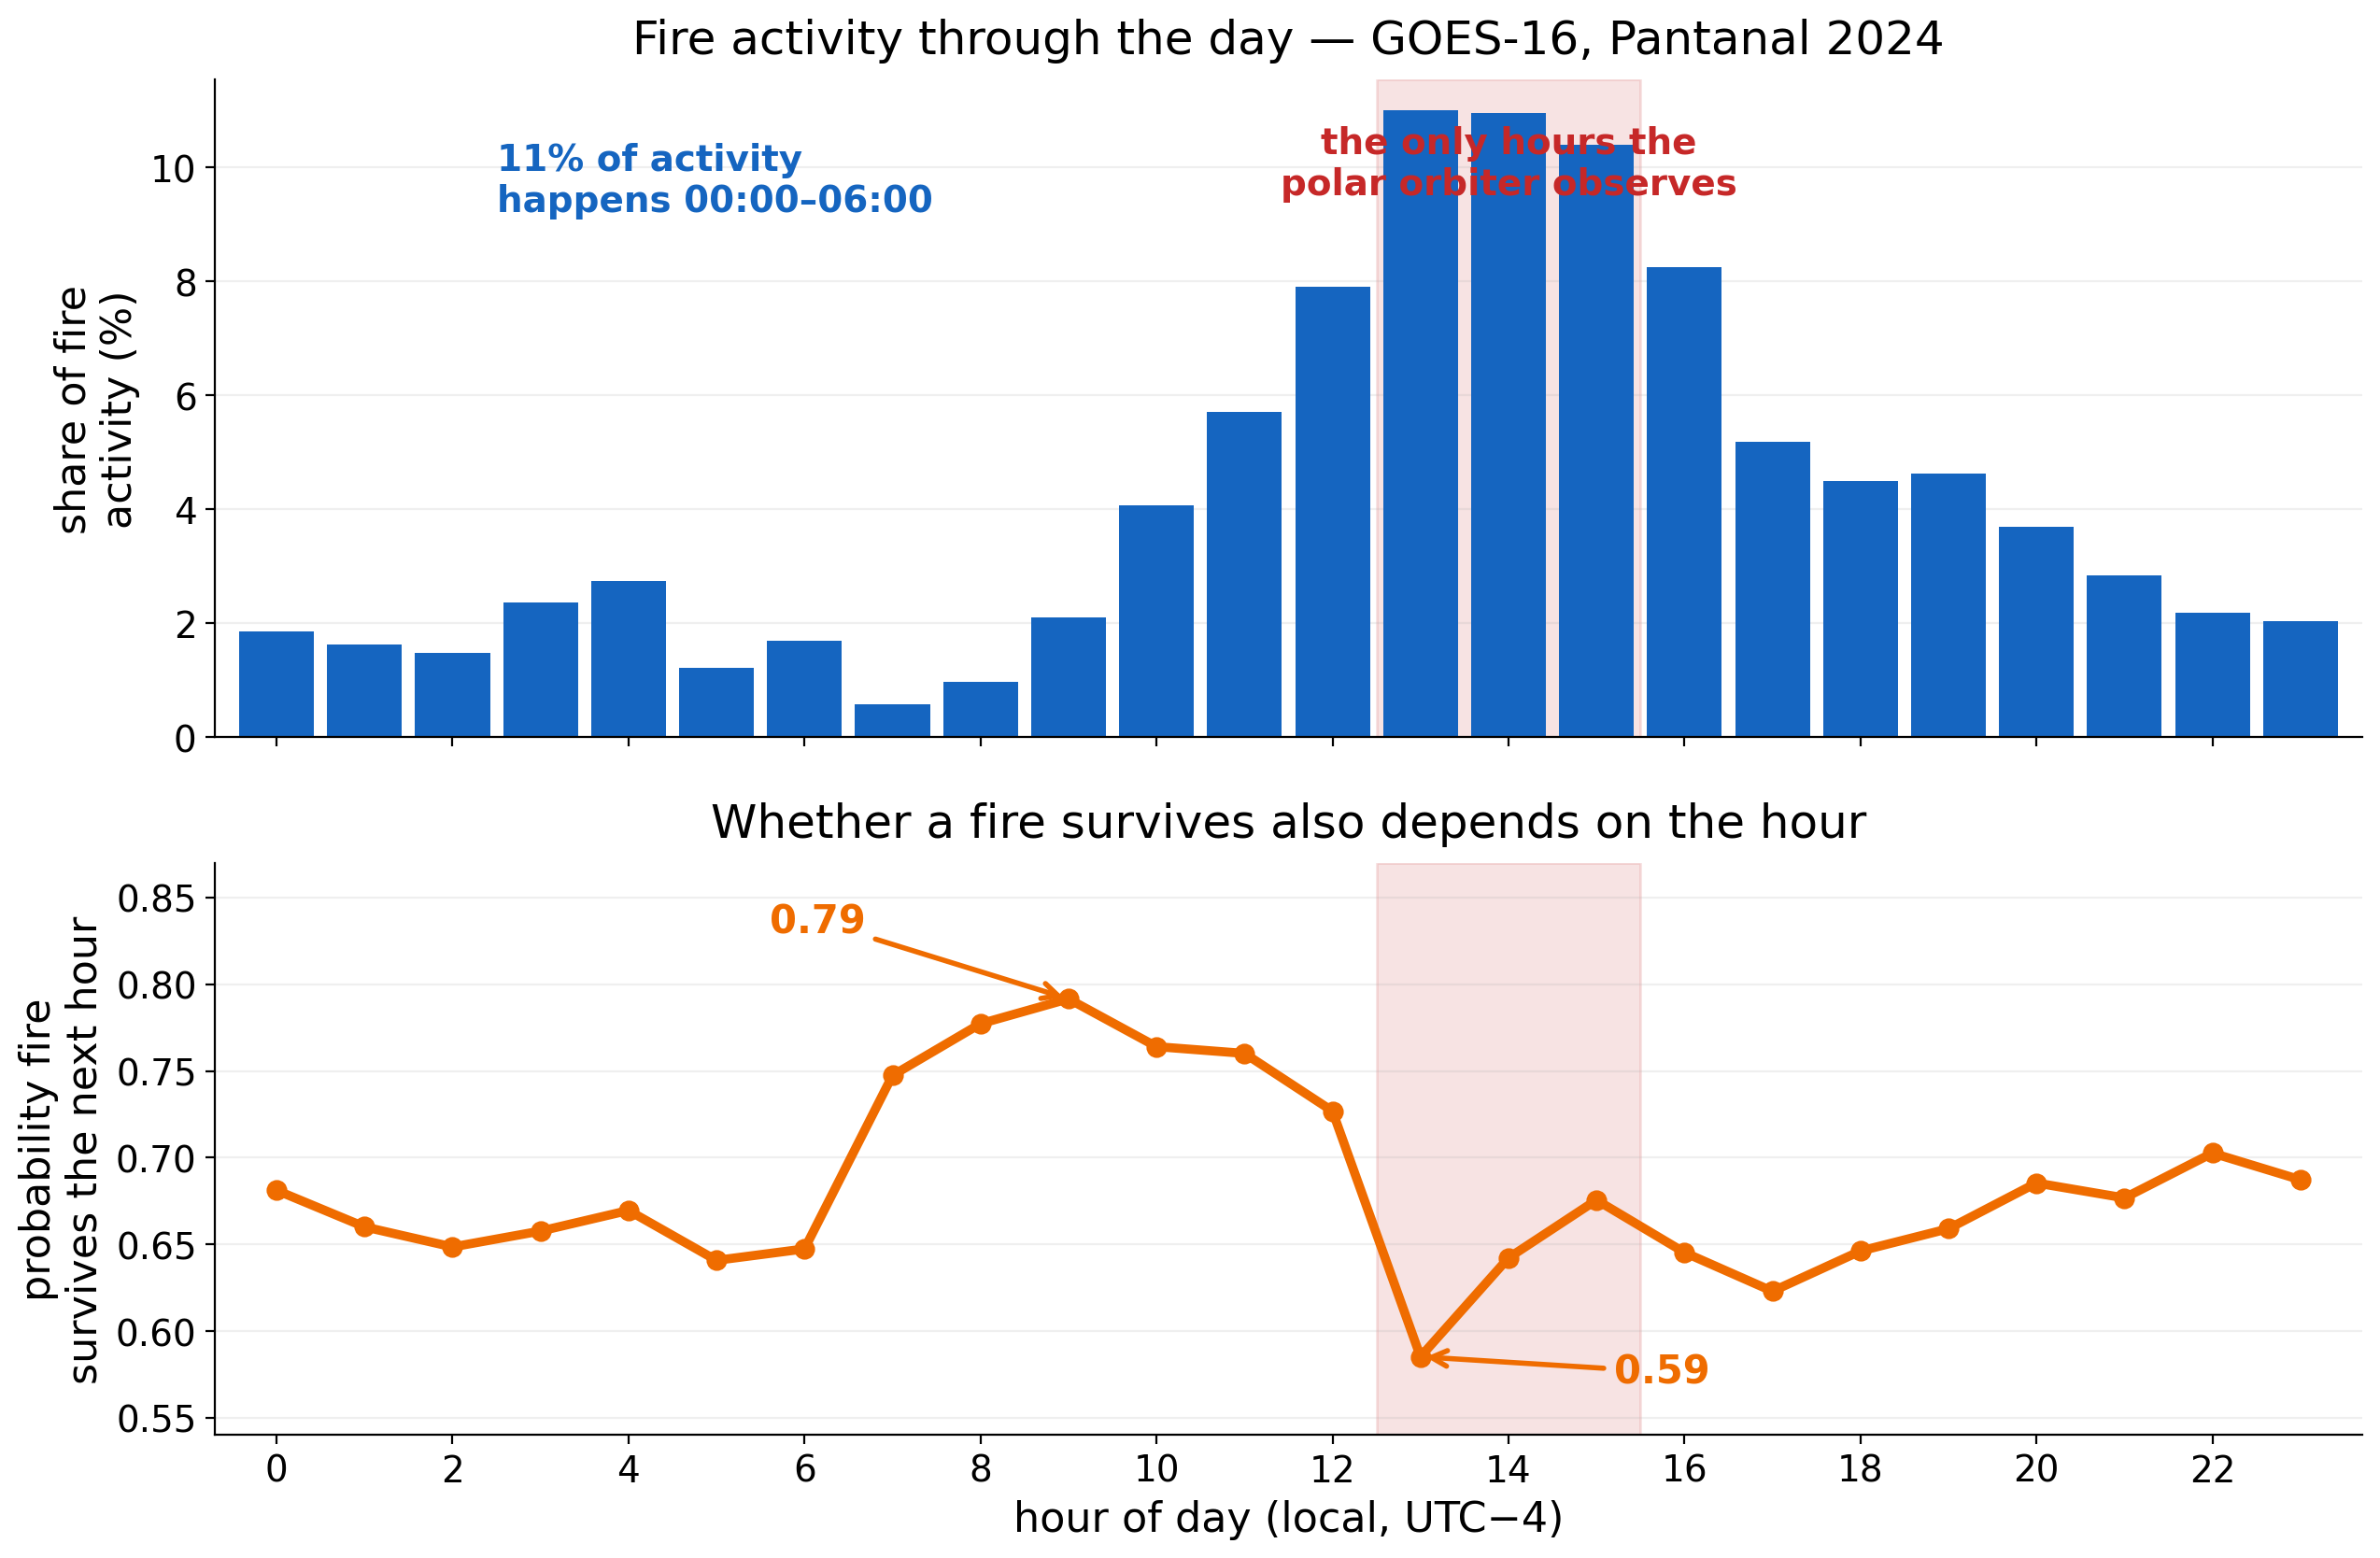

In [28]:
g28 = pd.read_parquet(GOES / "data" / "goes_model_table_2024.parquet").sort_values("time").reset_index(drop=True)
diurnal = g28.groupby("hour_local").agg(activity=("n_fire_px", "sum"), persistence=("persists_t1h", "mean"))
diurnal["activity share"] = diurnal.activity / diurnal.activity.sum()

aug_d = pd.read_csv(GOES / "results" / "goes_diurnal_202408.csv")
print(f"[saved] August: share of cell-hours burning peaks at {aug_d.prevalence.max():.2%} "
      f"({int(aug_d.loc[aug_d.prevalence.idxmax(), 'hour_local']):02d}:00 local) and bottoms at "
      f"{aug_d.prevalence.min():.2%} ({int(aug_d.loc[aug_d.prevalence.idxmin(), 'hour_local']):02d}:00), "
      f"a factor of {aug_d.prevalence.max() / aug_d.prevalence.min():.1f}")
print(f"[live]  2024: {diurnal.loc[0:5, 'activity share'].sum():.1%} of fire activity happens between 00:00 and 06:00 local time")
print(f"[live]  2024: chance a burning cell is still burning 1 h later peaks at {diurnal.persistence.max():.2f} "
      f"({diurnal.persistence.idxmax():02d}:00) and bottoms at {diurnal.persistence.min():.2f} ({diurnal.persistence.idxmin():02d}:00)")
show_figure("fig2_diurnal_cycle.png", width=820)

About one-tenth of all fire activity happens at night, entirely invisible to an afternoon polar orbiter. And the chance that a fire survives the next hour depends on the hour: it is lowest around midday, when many short-lived fires start and die. With GOES-16, the hour of day becomes a **legitimate physical feature** instead of a record of when the satellite passed.

### 6.4 The hourly model on 28 km cells

GOES fire was first aggregated onto the ERA5 grid (0.25°, about 28 km) and joined to the hourly weather. For every cell burning at hour *t*, two targets:

- `persists_t1h`: the same cell is still burning at *t* + 1 h;
- `spreads_t1h`: a neighbouring cell that was not burning at *t* is burning at *t* + 1 h.

Rows whose outcome hour was not observed (less than half the cell's pixels visible) were dropped, not labelled zero.

In [29]:
print(f"[live] {len(g28):,} burning cell-hours, base rates: persistence {g28.persists_t1h.mean():.3f}, "
      f"spread {g28.spreads_t1h.mean():.3f}\n")
monthly = g28.groupby(g28.time.dt.month).agg(rows=("cell", "size"), persists=("persists_t1h", "mean"),
                                             spreads=("spreads_t1h", "mean"))
monthly.index = pd.to_datetime(monthly.index, format="%m").strftime("%b")
display(monthly.T)

[live] 130,550 burning cell-hours, base rates: persistence 0.673, spread 0.207



time,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
rows,"6,134.0000","4,500.0000","7,617.0000","2,885.0000","5,398.0000","12,726.0000","9,629.0000","32,622.0000","30,787.0000","12,003.0000","3,989.0000","2,260.0000"
persists,0.5126,0.4458,0.4951,0.5310,0.6273,0.6971,0.6804,0.7468,0.7530,0.6574,0.5375,0.4765
spreads,0.1539,0.2304,0.2632,0.0943,0.0950,0.1842,0.1727,0.2373,0.2230,0.2167,0.1802,0.1447


Strong **seasonality**: a fire in February has roughly even odds of surviving the hour, one in September about three in four. A single test period averages over this, which is why results are also checked month by month (rolling origin, Section 6.6).

**Features** come in three nested blocks (lists imported from `train_goes_hourly.py`):

- **context**: position, hour of day and day of year (as smooth cycles);
- **fire state**: number of fire pixels, fire area, fire radiative power (FRP), fire in this cell 1–24 h ago, fire in neighbouring cells;
- **meteorology**: temperature, humidity, VPD and wind now, 1–12 h before, and over 24 h.

In [30]:
import train_goes_hourly as tgh

display(pd.DataFrame({"features": {k: len(v) for k, v in tgh.FEATURE_SETS.items()}}))
print("fire-state block:", ", ".join(tgh.FIRE_STATE))

,features
context,6
context_fire,29
context_fire_met,59


fire-state block: n_fire_px, fire_area_km2, fire_frac_of_cell, max_frp, sum_frp, max_area, max_temp, has_frp, has_area_temp, fire_lag1, fire_lag2, fire_lag3, fire_lag6, fire_lag12, fire_lag24, fire_hours_last6, fire_hours_last24, frp_lag1, npx_lag1, npx_delta, nb_cells_burning, nb_fire_px, nb_cells_burning_lag1


**"Not measured" is not "zero".** GOES-16 often detects a fire but cannot measure its power, area or temperature. These gaps were first filled with 0, and the model learned that "zero power" means "short-lived". In reality it was reading a *measurement-failure* flag disguised as a physical value. Missing values are now left missing (XGBoost handles them natively) and explicit flags (`has_frp`, `has_area_temp`) record whether each measurement exists.

In [31]:
print(f"[live] fire power was measured for {g28.has_frp.mean():.1%} of burning cell-hours")
display(g28.groupby("has_frp").persists_t1h.mean().rename(index={0: "power not measured", 1: "power measured"})
        .rename("share persisting 1 h later").to_frame())

[live] fire power was measured for 79.8% of burning cell-hours


,share persisting 1 h later
has_frp,
power not measured,0.4162
power measured,0.7385


### 6.5 Holdout: train January–August, test September–December

The test period starts after a **24-hour embargo**: consecutive hours of the same fire are almost identical, so without a gap the last training hour and the first test hour would be the same fire.

In [32]:
TARGETS_28 = {"persists_t1h": dict(metric="roc_auc", calibrate=False),
              "spreads_t1h": dict(metric="pr_auc", calibrate=True)}
tr28, te28 = tgh.split(g28, "2024-09-01", embargo_h=24)
print(f"train {len(tr28):,} rows | test {len(te28):,} rows")

if RECOMPUTE:
    hold28 = pd.concat([tgh.effect_size(tr28, te28, t, info["calibrate"], N_SEEDS).assign(target=t)
                        for t, info in TARGETS_28.items()], ignore_index=True)
    tag28 = "[live]"
else:
    hold28 = pd.read_csv(GOES / "results" / "holdout_effect_size.csv")
    tag28 = "[saved]"

order28 = list(tgh.FEATURE_SETS)
for t, info in TARGETS_28.items():
    print(f"\n{tag28} {t} ({info['metric']}, test base rate {te28[t].mean():.3f}):")
    display(summarise(hold28[hold28.target == t], info["metric"], "context", order28))

train 80,012 rows | test 49,039 rows

[saved] persists_t1h (roc_auc, test base rate 0.699):


,mean,std across seeds,gain,gain / noise (sigma)
feature_set,,,,
context,0.6415,0.0011,0.0000,0.0000
context_fire,0.8302,0.0002,0.1887,164.2215
context_fire_met,0.8308,0.0002,0.1893,164.7682



[saved] spreads_t1h (pr_auc, test base rate 0.214):


,mean,std across seeds,gain,gain / noise (sigma)
feature_set,,,,
context,0.3355,0.0020,0.0000,0.0000
context_fire,0.3908,0.0036,0.0553,15.1917
context_fire_met,0.3926,0.0019,0.0570,15.6775


**Knowing what the fire is doing now** lifts one-hour persistence from 0.64 to 0.83 ROC-AUC, an enormous effect (over 150σ). Adding the weather on top changes almost nothing. Over one hour, the weather does not change enough to alter a fire's fate.

### 6.6 Rolling origin: five monthly forecasts

One holdout gives one number. The **rolling origin** repeats the forecast five times: train through May, test June; train through June, test July; and so on to October. It shows whether a result holds across the season. The month-by-month results are used for the paired test in Section 8.

In [33]:
def rolling_28(df, seeds):
    rows = []
    for m in range(5, 10):
        start = pd.Timestamp(f"2024-{m + 1:02d}-01")
        tr, te = tgh.split(df, start, start + pd.DateOffset(months=1), embargo_h=24)
        for t, info in TARGETS_28.items():
            g = tgh.effect_size(tr, te, t, info["calibrate"], seeds).groupby("feature_set")[info["metric"]].mean()
            rows += [{"test_month": m + 1, "target": t, "feature_set": fs, "score": g[fs]} for fs in tgh.FEATURE_SETS]
    return pd.DataFrame(rows)

roll28 = rolling_28(g28, N_SEEDS) if RECOMPUTE else pd.read_csv(GOES / "results" / "rolling_origin.csv")
for t in TARGETS_28:
    piv = roll28[roll28.target == t].pivot(index="test_month", columns="feature_set", values="score")[order28]
    print(f"{tag28} {t}, score by test month:")
    display(piv.T)

[saved] persists_t1h, score by test month:


test_month,6,7,8,9,10
feature_set,,,,,
context,0.6334,0.6780,0.6358,0.6309,0.6321
context_fire,0.7913,0.8084,0.8065,0.8198,0.8280
context_fire_met,0.7939,0.8090,0.8002,0.8204,0.8303


[saved] spreads_t1h, score by test month:


test_month,6,7,8,9,10
feature_set,,,,,
context,0.2452,0.2452,0.3464,0.3646,0.3319
context_fire,0.2817,0.2937,0.3987,0.4184,0.3671
context_fire_met,0.2814,0.3047,0.4030,0.4189,0.3781


The fire-state block helps in all five months for both targets. Tuned models (XGBoost and random forest, Optuna) reach about the same level, ROC-AUC 0.830 for persistence: when the signal is this strong, tuning adds little.

### 6.7 Two silent bugs fixed while scaling to the full year

1. **A missing month.** A network interruption during the download of April 2024 aborted that month without any error, so the year silently had eleven months. Every download now retries with increasing delays, and failures are reported loudly.
2. **Shifted history.** "Fire 1 hour ago" was computed by taking the previous *row*. Where an hour was missing (a failed scan), it reached back 2 hours instead. The time axis is now a complete list of hours, so gaps stay gaps. About 1.6% of hours were affected, a bug that would never have shown in a score.

## 7. Stage 3: getting spread right at 2 km, and separating ignition

### 7.1 The 28 km spread target was not measuring spread

Three physical checks were applied to `spreads_t1h`:

In [34]:
cell_km = 0.25 * 111.2                                  # one 0.25° step of latitude, in km
print(f"[live] 1. Speed: reaching the next cell ({cell_km:.1f} km) within one hour needs a front moving at "
      f"{cell_km * 1000 / 3600:.1f} m/s. Even fast crown fires rarely exceed 1-3 m/s.")
print("[saved] 2. Direction: 25.4% of 'spread' events fell within 45 degrees of downwind, exactly the 25% "
      "expected at random (recorded by build_goes_split_targets.py).")

frp_q = pd.qcut(g28.sum_frp.rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
by_power = g28.groupby(frp_q, observed=True)[["spreads_t1h", "persists_t1h"]].mean()
by_power.columns = ["share 'spreading' (old target)", "share persisting"]
print("[live] 3. Fire power: by fire-power class (Q1 = weakest fifth of burning cells, Q5 = strongest)")
display(by_power.T)

[live] 1. Speed: reaching the next cell (27.8 km) within one hour needs a front moving at 7.7 m/s. Even fast crown fires rarely exceed 1-3 m/s.
[saved] 2. Direction: 25.4% of 'spread' events fell within 45 degrees of downwind, exactly the 25% expected at random (recorded by build_goes_split_targets.py).
[live] 3. Fire power: by fire-power class (Q1 = weakest fifth of burning cells, Q5 = strongest)


sum_frp,Q1,Q2,Q3,Q4,Q5
share 'spreading' (old target),0.1412,0.1868,0.2154,0.2357,0.2268
share persisting,0.4509,0.6660,0.7537,0.8544,0.9674


Persistence rises steeply with fire power (from 0.45 to 0.97). The old "spread" rate rises much less (0.14 to 0.23) and levels off in the top two classes. On this final version of the table the size check is weaker than first recorded: the scripts' notes quote a flat 0.20 / 0.17 / 0.23 / 0.25 / 0.24 from an earlier version of the table. The speed and direction checks are the decisive ones. The target was really measuring "some new fire appeared within about 28 km", mostly unrelated fires. The 28 km cell had been chosen to match the weather grid, but it threw away a factor of 14 in resolution in exactly the dimension where spread happens.

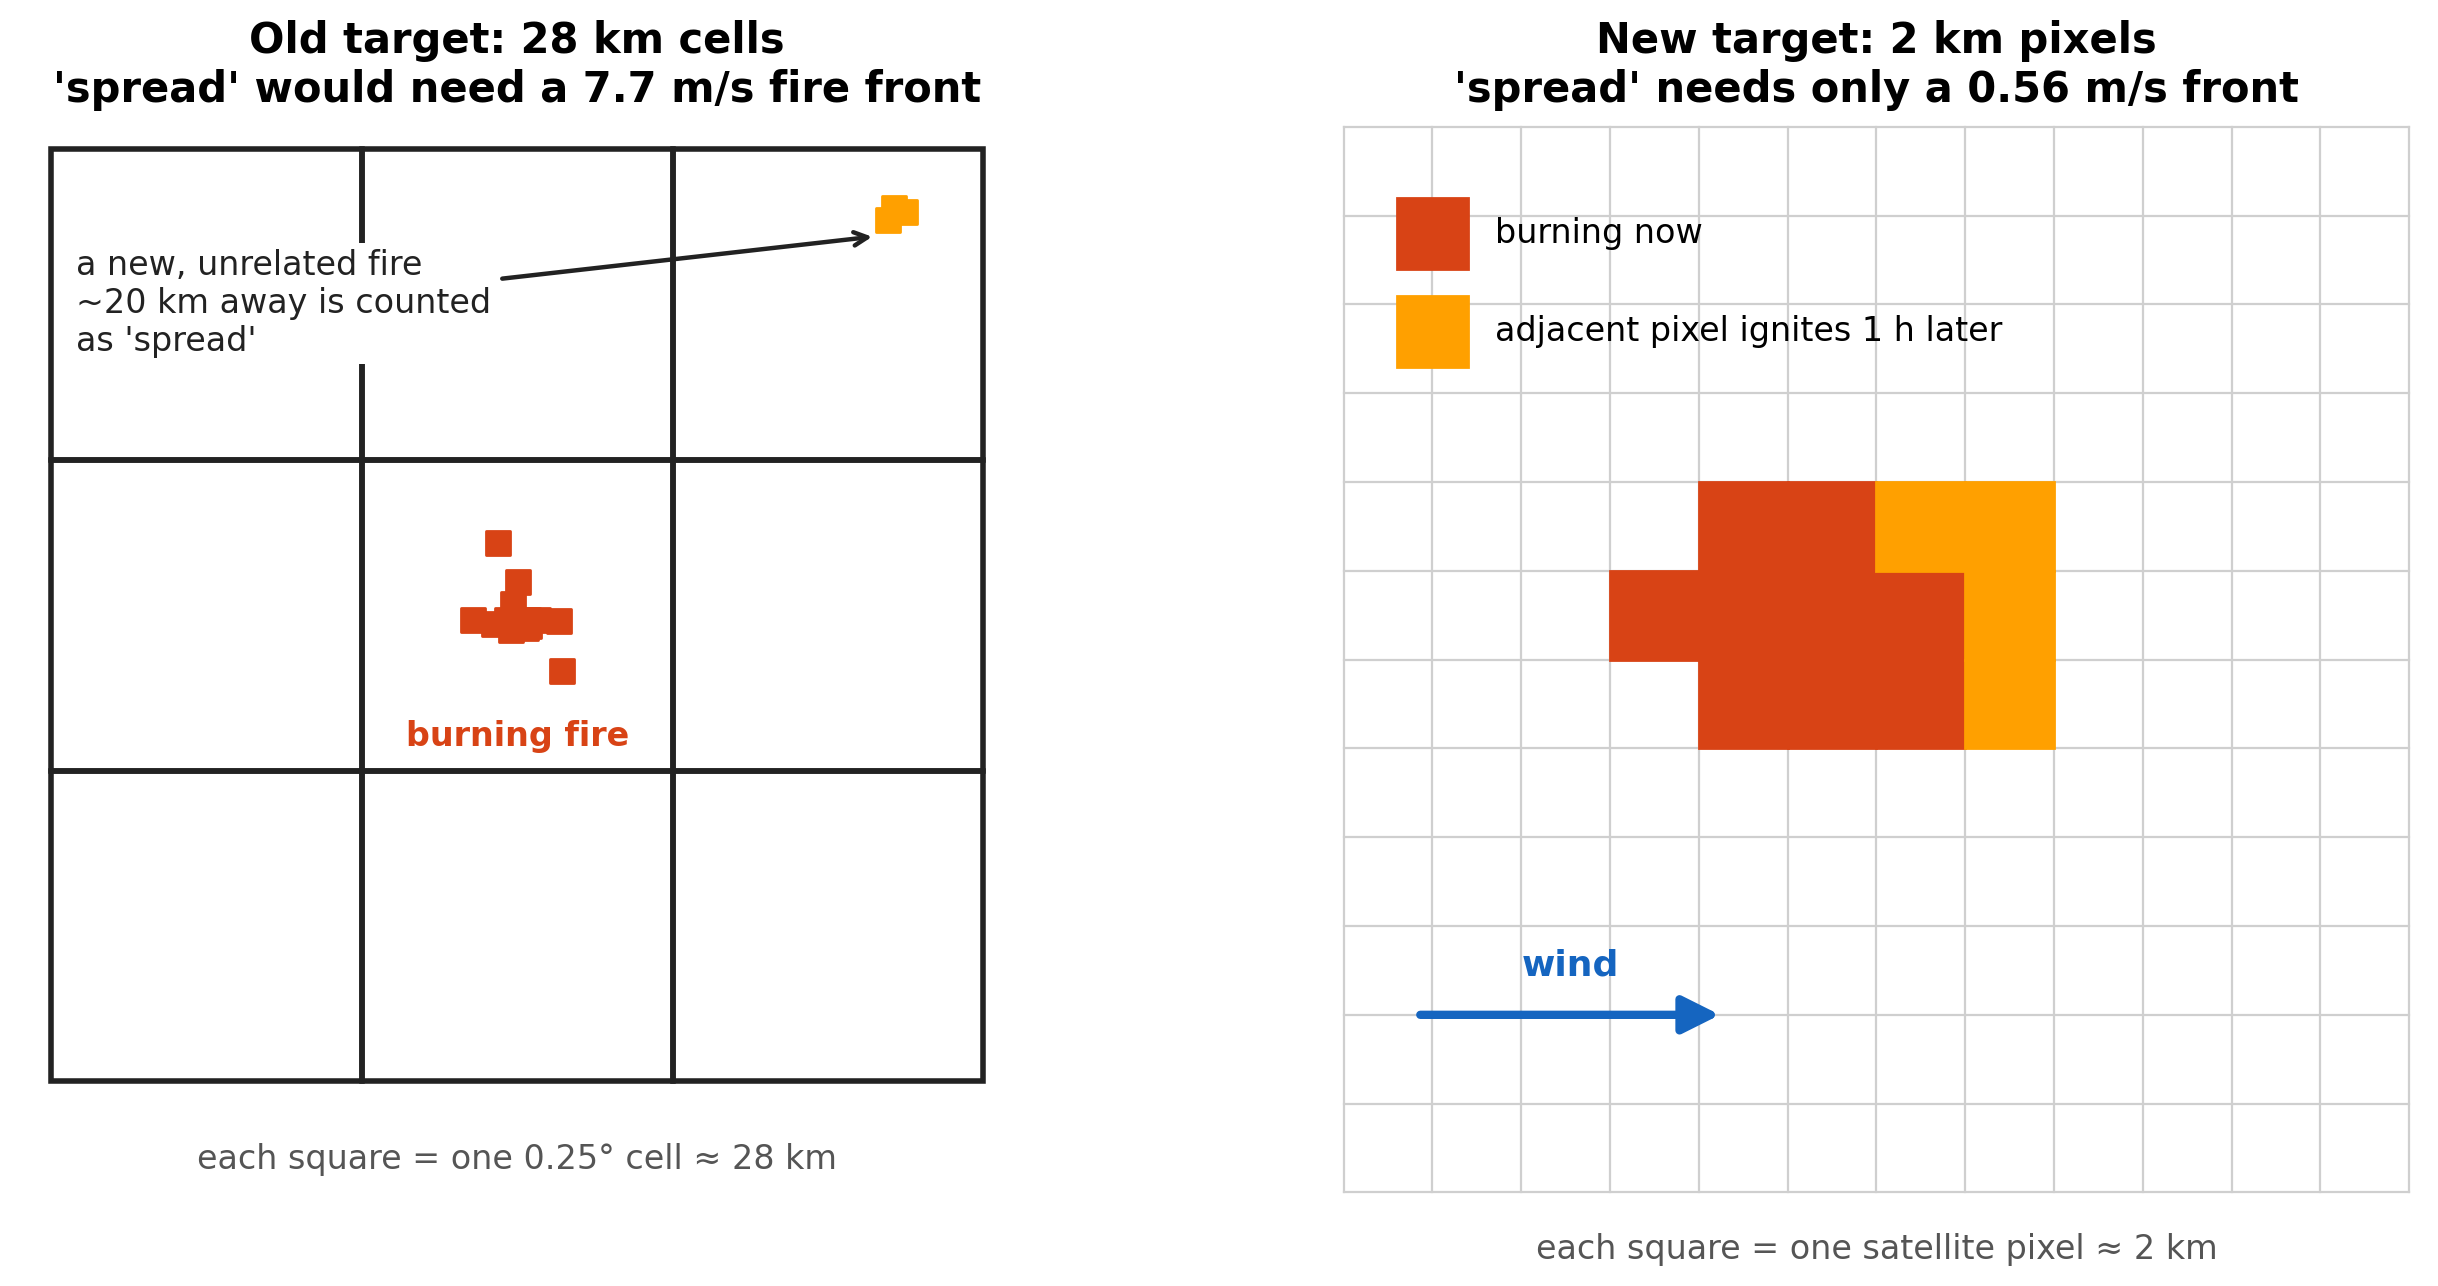

In [35]:
show_figure("fig_resolution.png")

### 7.2 The fix, part 1: store fire at native resolution

Every GOES-16 fire pixel of 2024 was stored with its exact position, time and measurements. Fire pixels are sparse, so a whole year is tiny. Any new target definition now takes minutes of computation instead of a full re-download.

In [36]:
pix_files = sorted((GOES / "data").glob("goes_fire_pixels_2024??.parquet"))
pixels = pd.concat([pd.read_parquet(f) for f in pix_files], ignore_index=True)
size_mb = sum(f.stat().st_size for f in pix_files) / 1e6
print(f"[live] {len(pixels):,} fire pixels in 2024, stored in {size_mb:.1f} MB across {len(pix_files)} monthly files")
print(f"[live] one 2 km pixel per hour = a front speed of {2000 / 3600:.2f} m/s: physically plausible")
display(pixels.head(3))

[live] 581,419 fire pixels in 2024, stored in 9.1 MB across 12 monthly files
[live] one 2 km pixel per hour = a front speed of 0.56 m/s: physically plausible


,time,scan_time,px_row,px_col,lat,lon,cell,mask_code,frp,area,temp
0,2024-01-01,2024-01-01 00:00:20,353,97,-19.7299,-58.7713,614,15,NaN,NaN,NaN
1,2024-01-01,2024-01-01 00:00:20,353,110,-19.7345,-58.5026,615,15,NaN,NaN,NaN
2,2024-01-01,2024-01-01 00:00:20,353,111,-19.7348,-58.4819,615,15,NaN,NaN,NaN


### 7.3 The fix, part 2: split the target into two questions

The old target mixed two processes with different causes:

- **Spread (2 km):** for each burning pixel with at least one unburnt neighbour, does an adjacent pixel ignite in the next hour? Pixels surrounded by fire on all eight sides are excluded: they have nowhere to go.
- **Ignition:** for each 0.25° cell with no fire in it or in the cells around it, does fire appear in the next hour? This is rare, so non-events were sampled at 20 per event. ROC-AUC is unaffected by this sampling; PR-AUC is only comparable between models on this same table.

In [37]:
import train_goes_split as tgs

spread = tgs.prepare(GOES / "data" / "goes_spread_2km_2024_01-12.parquet", "spreads_2km_t1h")
ign = tgs.prepare(GOES / "data" / "goes_ignition_2024_01-12.parquet", "ignites_t1h")
eligible = ign.drop_duplicates("time").n_eligible.sum()
print(f"[live] spread table  : {len(spread):,} rows, base rate {spread.spreads_2km_t1h.mean():.3f}")
print(f"[live] ignition table: {len(ign):,} rows, base rate {ign.ignites_t1h.mean():.3f} after sampling; "
      f"true hourly rate {ign.ignites_t1h.sum():,} / {eligible:,} = {ign.ignites_t1h.sum() / eligible:.2%}")

[live] spread table  : 478,640 rows, base rate 0.194
[live] ignition table: 599,471 rows, base rate 0.047 after sampling; true hourly rate 27,895 / 7,098,138 = 0.39%


### 7.4 The physical checks now pass

In [38]:
moved = spread[spread.spreads_2km_t1h == 1].spreads_downwind.dropna()
share = moved.mean()
z = (share - 0.25) / np.sqrt(0.25 * 0.75 / len(moved))
print(f"[live] downwind: {share:.1%} of {len(moved):,} spread events within 45 degrees of downwind "
      f"(random = 25%), z = {z:.1f}")

q5 = [f"Q{i}" for i in range(1, 6)]
checks = pd.DataFrame({
    "by fire power": spread.groupby(pd.qcut(spread.frp, 5, labels=q5), observed=True).spreads_2km_t1h.mean(),
    "by wind speed": spread.groupby(pd.qcut(spread.wind_speed, 5, labels=q5), observed=True).spreads_2km_t1h.mean(),
}).T
print("[live] share of burning pixels that spread within the hour, by class (Q1 = lowest fifth):")
display(checks)

bins = pd.cut(ign.dist_to_fire_km, [30, 60, 120, 250, 1e4], labels=["< 60 km", "60-120 km", "120-250 km", "> 250 km"])
print("[live] ignition rate (sampled table) by distance to the nearest active fire:")
display(ign.groupby(bins, observed=True).ignites_t1h.mean().rename("ignition rate").to_frame().T)

recent = ign.cell_fire_hours_last24 > 0
print(f"[live] {ign.loc[ign.ignites_t1h == 1, 'cell_fire_hours_last24'].gt(0).mean():.0%} of ignitions happen in cells "
      f"that burned in the previous 24 h; ignition rate there {ign.ignites_t1h[recent].mean():.0%} "
      f"vs {ign.ignites_t1h[~recent].mean():.1%} elsewhere")

[live] downwind: 28.6% of 93,017 spread events within 45 degrees of downwind (random = 25%), z = 25.6
[live] share of burning pixels that spread within the hour, by class (Q1 = lowest fifth):


,Q1,Q2,Q3,Q4,Q5
by fire power,0.1088,0.2118,0.2271,0.2372,0.2729
by wind speed,0.1327,0.1549,0.1831,0.2375,0.2635


[live] ignition rate (sampled table) by distance to the nearest active fire:


dist_to_fire_km,< 60 km,60-120 km,120-250 km,> 250 km
ignition rate,0.0829,0.0590,0.0392,0.0284


[live] 53% of ignitions happen in cells that burned in the previous 24 h; ignition rate there 26% vs 2.4% elsewhere


| Check | Old target (28 km) | New target (2 km) |
|---|---|---|
| Implied front speed | 7.7 m/s, impossible | 0.56 m/s, physical |
| Within 45° of downwind | 25.4%, random | 28.6%, z ≈ 26 |
| Spread rate, weakest to strongest fire power | 0.14 → 0.23, levels off | 0.11 → 0.27, rises steadily |
| Dependence on wind speed | not tested | doubles from calmest to windiest fifth |

A downwind share of 28.6% against 25% looks small, but with 93,017 events it is 25 standard errors away from chance. Many spread events are driven by things other than wind (slope, fuel, the fire's shape), so a modest but systematic preference is what physics predicts.

**Ignition behaves differently.** New fires appear close to existing fire, and more than half of "ignitions" occur in cells that burned in the previous day. Part of what is called ignition is fire **re-appearing** after a pause (smouldering that flares up, or a fire briefly hidden by smoke or a missed scan) rather than a brand-new start.

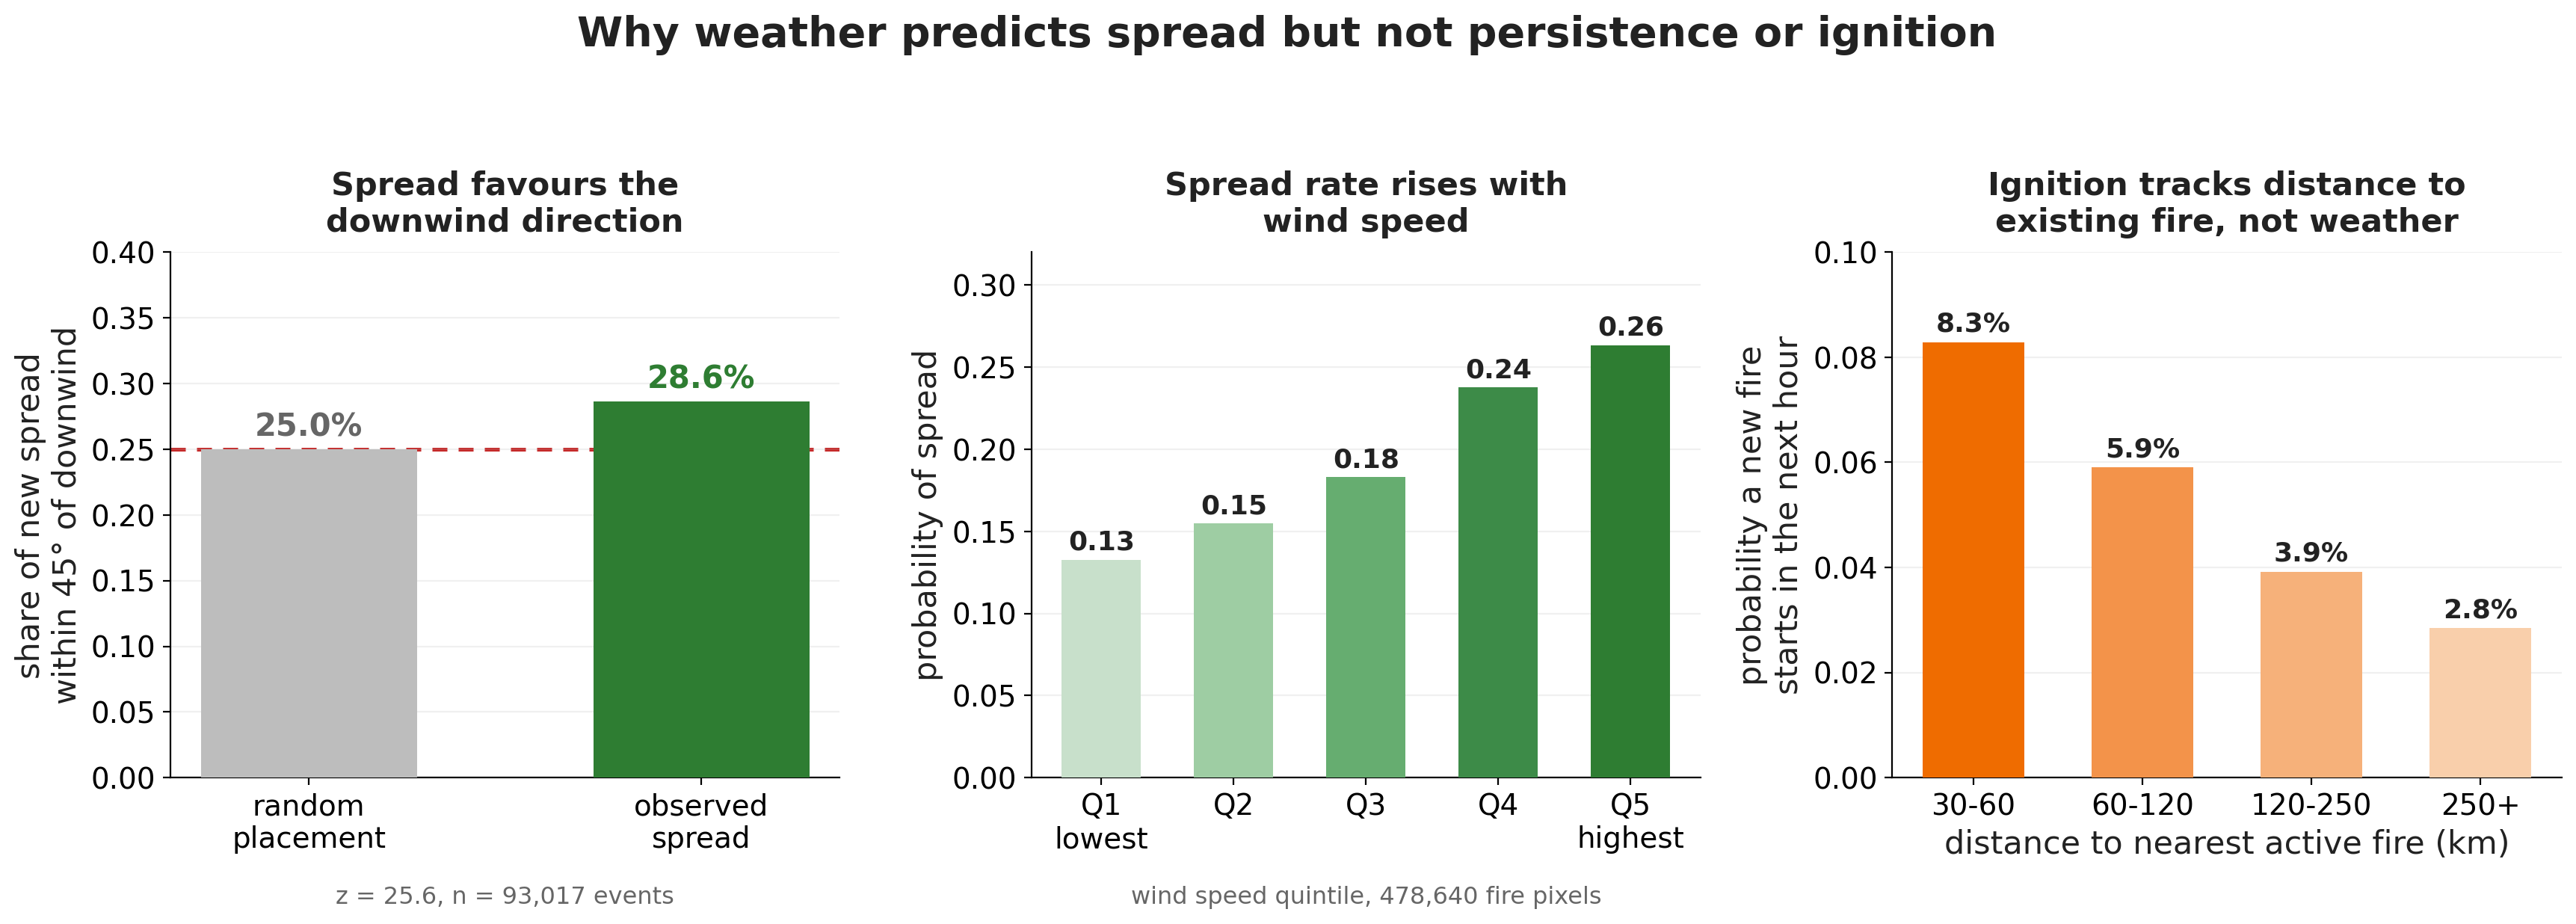

In [39]:
show_figure("fig5_spread_mechanism.png")

**Leakage guard.** Some columns of the spread table describe *where the fire went* (`spread_bearing`, `spreads_downwind`, `wind_spread_angle`). They are needed for the checks above but are only known after the fact, so they can never be features. The training script refuses to run if one appears in a feature set:

In [40]:
print("outcome-derived columns, never used as features:", sorted(tgs.LEAKY))
for name, sets in [("spread", tgs.SPREAD_SETS), ("ignition", tgs.IGNITION_SETS)]:
    for set_name, cols in sets.items():
        assert not (set(cols) & tgs.LEAKY)
    print(f"  {name}: no feature set contains them -> OK ({', '.join(f'{k} {len(v)}' for k, v in sets.items())} features)")

outcome-derived columns, never used as features: ['spread_bearing', 'spreads_downwind', 'wind_spread_angle']
  spread: no feature set contains them -> OK (context 6, context_fire 14, context_fire_met 20 features)
  ignition: no feature set contains them -> OK (context 6, context_activity 9, context_activity_met 13 features)


### 7.5 Results: holdout September–December

Same protocol as before: train January–August, 24 h embargo, test September–December, fixed settings over 5 seeds. Spread is scored by PR-AUC (base rate about 20%), ignition by ROC-AUC (its PR-AUC is distorted by the sampling).

In [41]:
SPLIT_TASKS = {"spread": (spread, "spreads_2km_t1h", tgs.SPREAD_SETS, "pr_auc", "spread2km"),
               "ignition": (ign, "ignites_t1h", tgs.IGNITION_SETS, "roc_auc", "ignition")}

def holdout_split(df, target, sets, seeds):
    cut = pd.Timestamp("2024-09-01")
    tr, te = df[df.time < cut - pd.Timedelta(hours=24)], df[df.time >= cut]
    return tgs.effect_size(tr, te, target, sets, seeds, None), te[target].mean()

hold_split = {}
for name, (df, target, sets, metric, tag) in SPLIT_TASKS.items():
    if RECOMPUTE:
        runs, base = holdout_split(df, target, sets, N_SEEDS); label = "[live]"
    else:
        runs = pd.read_csv(GOES / "results" / f"{tag}_effect_size.csv")
        base = df.loc[df.time >= "2024-09-01", target].mean(); label = "[saved]"
    hold_split[name] = runs
    print(f"{label} {name} ({metric}, test base rate {base:.3f}):")
    display(summarise(runs, metric, "context", list(sets)))

[saved] spread (pr_auc, test base rate 0.196):


,mean,std across seeds,gain,gain / noise (sigma)
feature_set,,,,
context,0.3421,0.0023,0.0000,0.0000
context_fire,0.4065,0.0018,0.0645,28.1570
context_fire_met,0.4105,0.0013,0.0684,29.8999


[saved] ignition (roc_auc, test base rate 0.047):


,mean,std across seeds,gain,gain / noise (sigma)
feature_set,,,,
context,0.6573,0.0008,0.0000,0.0000
context_activity,0.8167,0.0015,0.1594,103.4713
context_activity_met,0.8166,0.0013,0.1593,103.3941


In [42]:
print("[saved] best tuned models, test Sep-Dec 2024:")
best = []
for name, (df, target, sets, metric, tag) in SPLIT_TASKS.items():
    m = pd.read_csv(GOES / "results" / f"{tag}_metrics.csv")
    m = m[m.feature_set == list(sets)[-1]]
    best.append(m[["model", "roc_auc", "pr_auc", "prevalence", "lift_over_prevalence"]].assign(target=name))
display(pd.concat(best).set_index(["target", "model"]))

imp = pd.read_csv(GOES / "results" / "ignition_importance.csv")
imp = imp[(imp.model == "XGBoost") & (imp.feature_set == "context_activity_met")]
print("[saved] ignition model (XGBoost), most-used features:")
display(imp.sort_values("importance", ascending=False).head(6)[["feature", "importance"]].set_index("feature").T)

[saved] best tuned models, test Sep-Dec 2024:


roc_auc  pr_auc  prevalence  lift_over_prevalence
target   model                                                          
spread   XGBoost        0.7455  0.4072      0.1957                2.0809
         RandomForest   0.7381  0.4031      0.1957                2.0598
ignition XGBoost        0.8153  0.3470      0.0465                7.4606
         RandomForest   0.8160  0.3346      0.0465                7.1955

[saved] ignition model (XGBoost), most-used features:


feature,cell_fire_hours_last24,dist_to_fire_km,hour_cos,lat,lon,doy_cos
importance,0.5968,0.0695,0.0579,0.0489,0.0414,0.0298


- **Spread (2 km):** ROC-AUC about 0.75 and a lift of about 2.1×, up from 1.8× on the old target. The physically correct target is also the better-predicted one.
- **Ignition:** ROC-AUC about 0.82 and a lift of about 7.5× (on the sampled table). The model leans heavily on whether the cell burned in the last 24 h, consistent with the re-appearance finding in 7.4.

## 8. Does weather matter? The paired test

This question was asked at every stage. The final answer uses the **five monthly forecasts** (test months June to October 2024). In each month, the model *with* meteorology is compared with the same model *without* it, on exactly the same fires. Taking the difference month by month cancels out the fact that some months are simply easier than others: this is a **paired** comparison.

For each target the month-by-month gains are combined as in Section 2.3: mean, standard deviation, $t$, the p-value (4 degrees of freedom for 5 months), and a 95% confidence interval (mean ± 2.776 × standard error).

In [43]:
from scipy import stats

if RECOMPUTE:
    roll_split = {}
    for name, (df, target, sets, metric, tag) in SPLIT_TASKS.items():
        rows = []
        for m in range(5, 10):
            start = pd.Timestamp(f"2024-{m + 1:02d}-01")
            tr = df[df.time < start - pd.Timedelta(hours=24)]
            te = df[(df.time >= start) & (df.time < start + pd.DateOffset(months=1))]
            g = tgs.effect_size(tr, te, target, sets, N_SEEDS, None).groupby("feature_set")[metric].mean()
            rows += [{"test_month": m + 1, "feature_set": fs, "score": g[fs]} for fs in sets]
        roll_split[name] = pd.DataFrame(rows)
else:
    roll_split = {name: pd.read_csv(GOES / "results" / f"{task[4]}_rolling.csv") for name, task in SPLIT_TASKS.items()}


def monthly_gain(roll, with_met, without_met):
    piv = roll.pivot(index="test_month", columns="feature_set", values="score")
    return piv[with_met] - piv[without_met]


def paired_test(d):
    d = np.asarray(d, dtype=float)
    n, mean, sd = len(d), d.mean(), d.std(ddof=1)
    se = sd / np.sqrt(n)
    t = mean / se
    t_crit = stats.t.ppf(0.975, n - 1)
    return {"mean gain": mean, "sd": sd, "t": t, "p-value": 2 * stats.t.sf(abs(t), n - 1),
            "95% CI low": mean - t_crit * se, "95% CI high": mean + t_crit * se,
            "months improved": f"{(d > 0).sum()}/{n}"}

gains = {
    "persistence 1 h (ROC-AUC)": monthly_gain(roll28[roll28.target == "persists_t1h"], "context_fire_met", "context_fire"),
    "spread 2 km (PR-AUC)": monthly_gain(roll_split["spread"], "context_fire_met", "context_fire"),
    "ignition (ROC-AUC)": monthly_gain(roll_split["ignition"], "context_activity_met", "context_activity"),
    "old 28 km spread (PR-AUC)": monthly_gain(roll28[roll28.target == "spreads_t1h"], "context_fire_met", "context_fire"),
}
print("Gain from adding weather, by test month:")
display(pd.DataFrame(gains).T.round(4))
paired = pd.DataFrame({k: paired_test(v) for k, v in gains.items()}).T
display(paired)
print(f"Strict threshold for three tests (Bonferroni): p < {0.05 / 3:.4f}")

Gain from adding weather, by test month:


test_month,6,7,8,9,10
persistence 1 h (ROC-AUC),0.0026,0.0006,-0.0063,0.0006,0.0023
spread 2 km (PR-AUC),0.0216,0.0129,0.0143,0.0033,0.0070
ignition (ROC-AUC),0.0035,0.0005,0.0014,-0.0010,-0.0035
old 28 km spread (PR-AUC),-0.0004,0.0110,0.0043,0.0005,0.0111


,mean gain,sd,t,p-value,95% CI low,95% CI high,months improved
persistence 1 h (ROC-AUC),-0.0000,0.0036,-0.0111,0.9917,-0.0045,0.0045,4/5
spread 2 km (PR-AUC),0.0118,0.0070,3.7603,0.0198,0.0031,0.0206,5/5
ignition (ROC-AUC),0.0002,0.0026,0.1479,0.8896,-0.0031,0.0034,3/5
old 28 km spread (PR-AUC),0.0053,0.0055,2.1425,0.0988,-0.0016,0.0121,4/5


Strict threshold for three tests (Bonferroni): p < 0.0167


**Worked example, spread.** Adding weather improved the spread forecast in all five months. The mean gain is +0.0118 PR-AUC with a standard deviation of 0.0070, so the uncertainty of the mean is 0.0070 / √5 ≈ 0.0031 and t ≈ 3.8. With five months, a t this large happens by chance only about 2% of the time (p ≈ 0.020), and the 95% interval lies entirely above zero.

**How strong is the evidence?** p = 0.020 is below the usual 0.05. Because three targets were tested, the strict Bonferroni rule asks for p < 0.0167, so the result is just short of conclusive by that standard. It is supported by its consistency (5 of 5 months) and by independent physical evidence (Section 7.4). The monthly folds also share part of their training data, so they are not fully independent. More years of data would settle it.

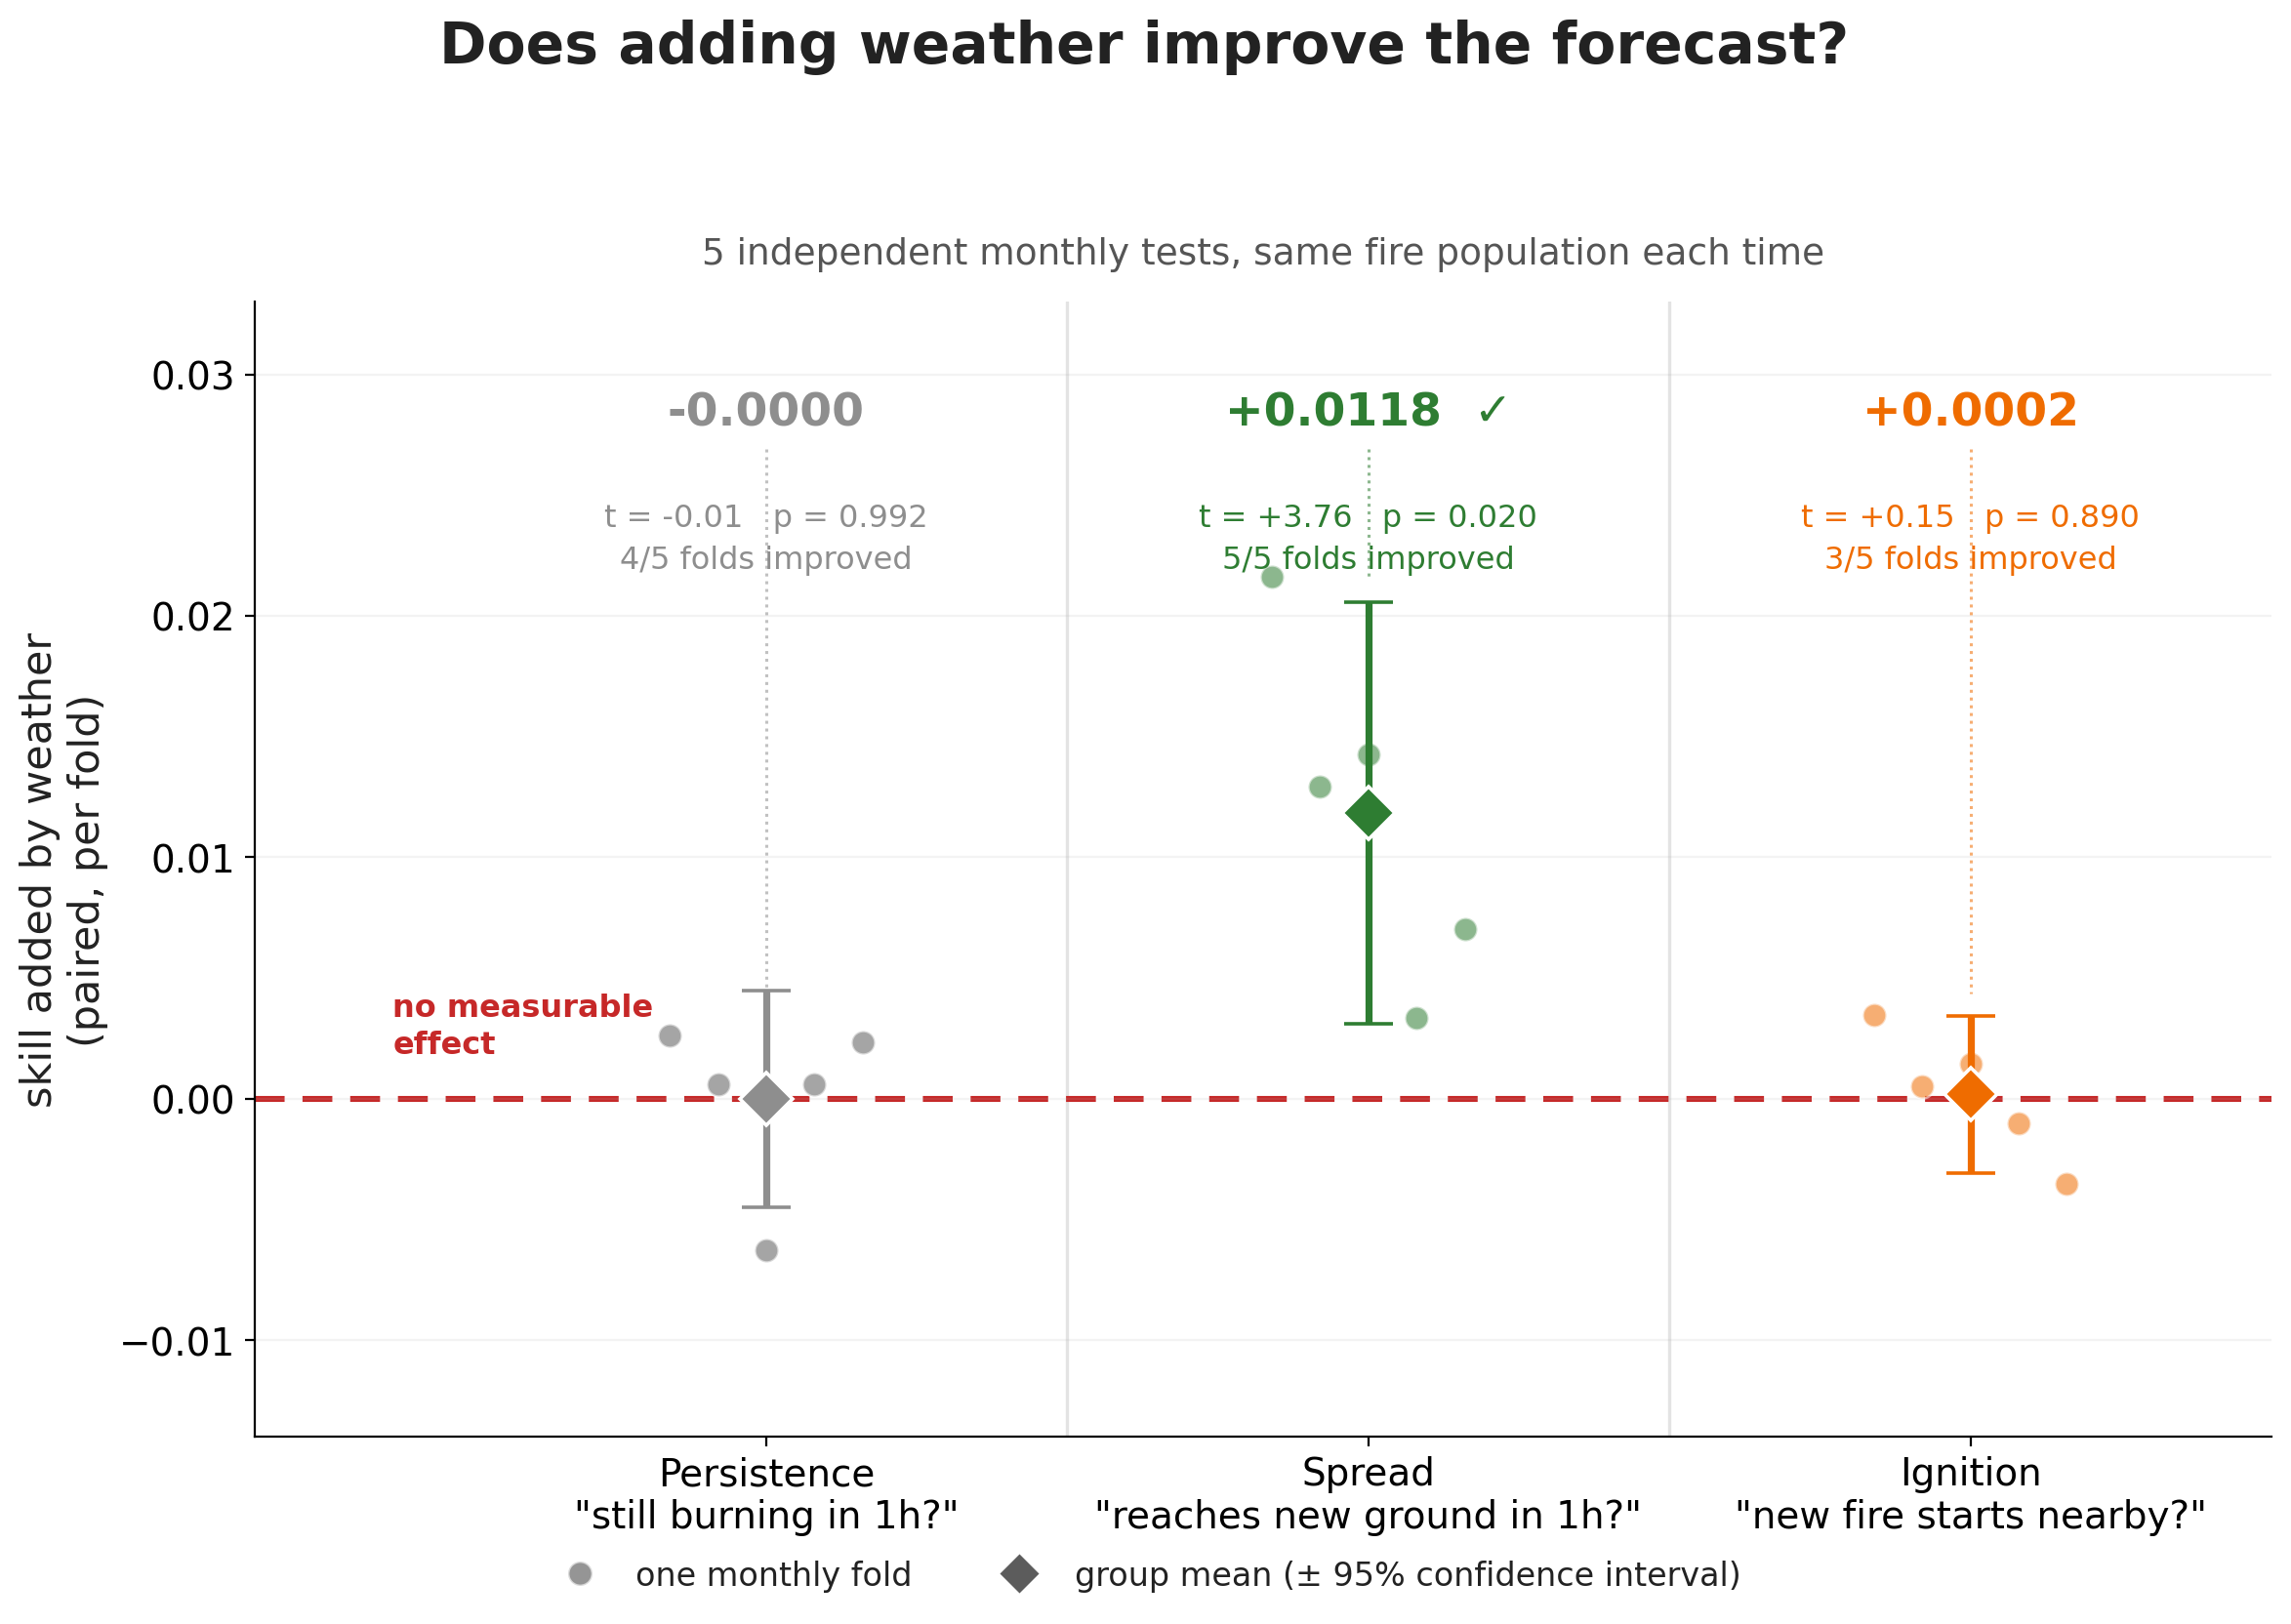

In [44]:
show_figure("fig4_weather_effect_by_target.png", width=780)

### What the result means physically

- **Persistence follows the fire's momentum.** Whether a fire still burns in an hour is decided by what it is doing now: its size, power and recent history. The weather does not change enough within an hour to overturn that. (At the ~24 h horizon of the INPE model, by contrast, hourly wind *did* help persistence: over a day, weather has time to act.)
- **Spread follows wind and dryness.** Fire advancing into unburnt vegetation is exactly what wind and dry air control, and the data show it: spread favours downwind, and doubles from the calmest to the windiest conditions.
- **Ignition follows people and existing fire.** New fires appear near existing fire activity and in recently burned cells, the signature of human ignition along the same roads, farms and clearing fronts, and of fires flaring up again.

"Weather adds nothing to the ignition forecast" does **not** mean weather has nothing to do with fire. It means that once we know where fire is active right now, the weather adds no further *hour-scale* information. The dry season is why there is fire at all; that information is already contained in the current fire activity and the season features.

Fixing the spread target roughly **doubled** the measured weather effect (from +0.005 to +0.012) and made it consistent across months. On the old 28 km target it was hidden.

## 9. The scoreboard

The five final models, each with its best tuned score on its own test period. ROC-AUC is used because it is comparable across targets whose base rates range from 5% to 70%.

[saved] final models (base rate of ignition is after sampling; the true hourly rate is about 0.4%):


,data,horizon,base rate,ROC-AUC
question,,,,
Will this fire still burn in 1 hour?,"GOES-16, 2024",1 h,70%,0.830
Will a new fire start nearby in 1 hour?,"GOES-16, 2024",1 h,5%,0.815
Will this fire spread to adjacent 2 km ground in 1 hour?,"GOES-16, 2024",1 h,20%,0.745
Will this fire still burn tomorrow?,"INPE, 2019-2024",~24 h,40%,0.670
Will fire spread around it by tomorrow?,"INPE, 2019-2024",~24 h,28%,0.652


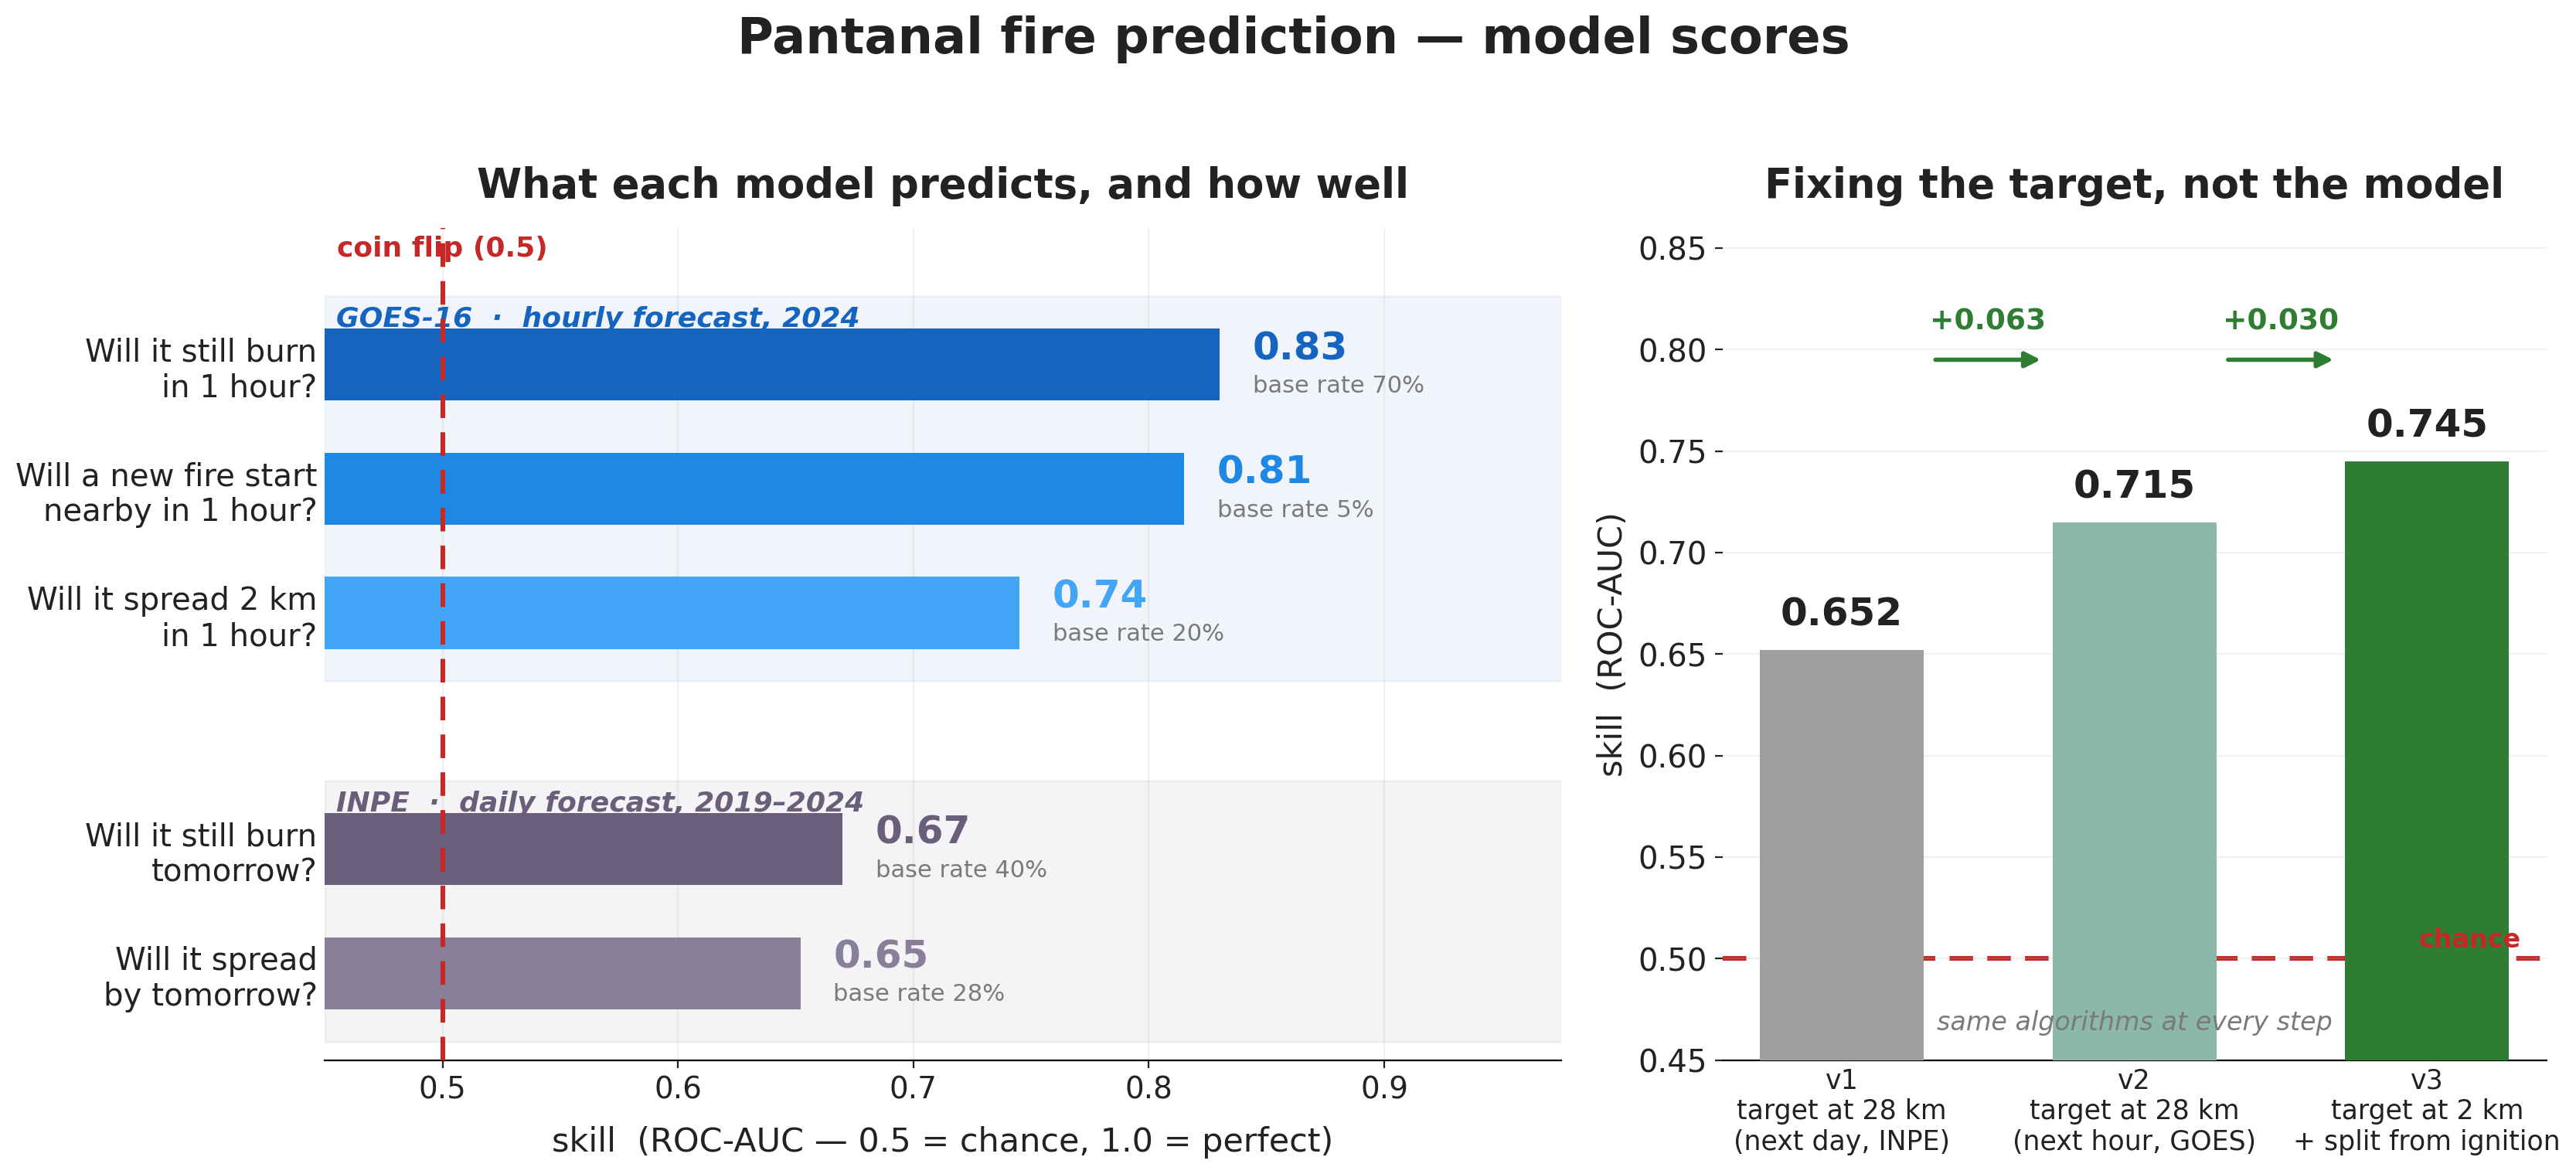

In [45]:
def pick(path, **where):
    d = pd.read_csv(path)
    for k, v in where.items():
        d = d[d[k] == v]
    return d.iloc[0]

board = [
    ("Will this fire still burn in 1 hour?", "GOES-16, 2024", "1 h",
     pick(GOES / "results" / "holdout_metrics.csv", target="persists_t1h", model="XGBoost", feature_set="context_fire_met")),
    ("Will a new fire start nearby in 1 hour?", "GOES-16, 2024", "1 h",
     pick(GOES / "results" / "ignition_metrics.csv", model="XGBoost", feature_set="context_activity_met")),
    ("Will this fire spread to adjacent 2 km ground in 1 hour?", "GOES-16, 2024", "1 h",
     pick(GOES / "results" / "spread2km_metrics.csv", model="XGBoost", feature_set="context_fire_met")),
    ("Will this fire still burn tomorrow?", "INPE, 2019-2024", "~24 h",
     pick(HOURLY / "results" / "final_test_metrics_hourly.csv", target="persists_t1", model="XGBoost",
          feature_set="with_hourly_wind", period="test_full")),
    ("Will fire spread around it by tomorrow?", "INPE, 2019-2024", "~24 h",
     pick(HOURLY / "results" / "final_test_metrics_hourly.csv", target="spreads_t1", model="XGBoost",
          feature_set="with_hourly_wind", period="test_full")),
]
scoreboard = pd.DataFrame([{"question": qn, "data": src, "horizon": hz,
                            "base rate": r.get("prevalence", r.get("prevalence_positive")),
                            "ROC-AUC": r.roc_auc} for qn, src, hz, r in board]).set_index("question")
print("[saved] final models (base rate of ignition is after sampling; the true hourly rate is about 0.4%):")
display(scoreboard.style.format({"base rate": "{:.0%}", "ROC-AUC": "{:.3f}"}))
show_figure("fig3_scoreboard.png")

All five models have real skill. The hourly models score higher partly because one hour ahead is easier than one day ahead, and partly because GOES-16 gives a much richer description of the fire's current state.

The right-hand panel of the figure carries the project's main methodological lesson: the spread model went from 0.652 to 0.715 to 0.745 with **the same algorithms at every step**. What changed was the target: first made hourly, then defined at the right spatial scale and separated from ignition.

## 10. Problems found and fixed

Every one of these would have produced convincing but wrong numbers, silently.

| Problem | Consequence | Fix |
|---|---|---|
| Daily table keeps only fires lasting ≥ 2 days | persistence 0.93 is mostly an artefact (one-line rule: 0.905) | reported; hourly table unfiltered |
| Unseeded Optuna search | identical runs gave 0.631 and 0.601 | seeded search; multi-seed comparisons |
| Time to next overpass from Pantanal detections only | target leak (0.218 vs 0.477) | regional overpass time, then dropped |
| Heatwave "hours since peak" on all-zero windows | calm confused with decayed | sentinel value −1 |
| Biome filter applied before the observation test | 433 instead of 76 clusters wrongly dropped | scope by state first |
| Fire chains crossing the train/test cut | same fire on both sides | chains purged |
| Timing features | high importance, but made the model worse | removed |
| INPE zero-fill hourly target | hour of day alone predicts "fire" | switched to GOES-16 |
| Decoding the full GOES disk | 3.3 s per file | windowed read, 83 ms |
| Network drop during download | April 2024 silently missing | retries with backoff, loud failures |
| Lags built from observed rows | "1 h ago" reached 2 h back (~1.6% of hours) | complete hourly time axis |
| Missing fire power stored as 0 | model learned a measurement flag | keep missing + explicit flags |
| 28 km spread target | not physical (7.7 m/s, random direction) | 2 km pixels, spread split from ignition |
| Wind direction convention (daily notebook) | alignment sign possibly inverted | store the "blows to" direction only |

Three lessons generalise beyond this project:

1. **Feature importance is not usefulness.** Test by training with and without, against the noise floor.
2. **Absence of evidence is not evidence of absence.** A fire not detected is not necessarily out; unobserved outcomes must be removed, not labelled zero.
3. **The target matters more than the algorithm.** Most of the progress came from defining the question correctly.

## 11. Limitations and next steps

**Limitations**

- **One year of GOES-16 data** (2024, a severe year). The INPE work showed that one year cannot capture differences between years.
- **The monthly folds cover the fire season only** (June–October); wet-season-only conditions are untested.
- **Different study areas:** GOES models cover the Pantanal and its surroundings (including Bolivia and Paraguay), the INPE models only the Brazilian Pantanal biome.
- **Weather at 28 km for fire at 2 km:** local winds around a fire are not resolved, so the weather effect on spread is probably underestimated.
- **One scan per hour** out of six: fires shorter than an hour can be missed.
- **Missing drivers:** fuel, land use, soil moisture, rainfall, flooding and human activity are not in the data.
- **The weather result is strong but not definitive** (p = 0.020, just above the strict threshold of 0.0167).

**Next steps** (detailed in the meeting document and the report's conclusion)

1. Extend GOES-16 to 2020–2024 (about 44,600 files, ~76 GB), which settles the weather result across contrasting years.
2. Measure the weather effect at lead times of 1, 3, 6, 12, 24 and 48 h, to find where weather starts to matter for persistence.
3. Separate true new ignitions from fires re-appearing, then redo the weather test on true ignitions.
4. Restrict the GOES models to the Pantanal biome; add finer weather (ERA5-Land, ~9 km), rainfall and soil moisture.
5. For a benchmark paper: a second region, deep-learning baselines, and a public release of data and code.

## Appendix A: rebuilding everything from raw data

This notebook reads files the pipeline already produced. To rebuild them from scratch, run these scripts in order. ERA5 needs a personal Copernicus CDS account and API key in your `.cdsapirc` file; GOES-16 and INPE data are public.

**Stage 1 (in `hourly_model/`):**
```bash
python build_fire_events_hourly.py --years 2019-2024 --states "MATO GROSSO DO SUL,MATO GROSSO"
python download_era5_pantanal.py --years 2019-2024      # several hours
python build_hourly_dataset.py
python feature_set_effect_size.py --seeds 5
# then run ml_persistence_spread_hourly.ipynb for the tuned models
```

**Stages 2–3 (in `goes_hourly_model/`):**
```bash
python build_goes_hourly.py --year 2024 --month 1      # downloads GOES-16, 1 scan per hour;
                                                       # run once per month, --month 1 to --month 12
python validate_goes_vs_inpe.py --year 2024 --month 8
python build_goes_model_table.py
python train_goes_hourly.py --mode both --trials 20 --seeds 5
python build_goes_pixels.py --year 2024 --months 1-12
python build_goes_split_targets.py --year 2024 --months 1-12
python train_goes_split.py --period 2024_01-12
python make_presentation_figures.py
python make_scoreboard_figure.py
python make_weather_effect_figures.py
```
Each script prints its options with `--help`.

## Appendix B: glossary

| Term | Meaning |
|---|---|
| Base rate / prevalence | How often the predicted event happens in the data |
| Cross-validation | Training on part of the data and checking on another part, to choose settings without touching the test set |
| DBSCAN | A clustering method that groups points closer than a set distance |
| Embargo | A time gap between training and test data, so the same event is not on both sides |
| ERA5 | ECMWF's global hourly reanalysis of the atmosphere |
| Feature | An input variable given to the model |
| FRP | Fire radiative power: energy a fire releases per second, measured from space (MW) |
| Fold | One train/test round in a repeated evaluation |
| Geostationary satellite | A satellite that stays above one point of the equator and observes continuously |
| Hyperparameter | A setting of the learning algorithm chosen by the user (number of trees, depth, ...) |
| Leakage | Information about the answer hidden in the inputs |
| Lift | PR-AUC divided by the base rate |
| Noise floor | How much a score varies through randomness alone |
| Optuna | A tool that searches for good hyperparameters automatically |
| p-value | Probability of a difference at least this large if there were truly no effect |
| Polar-orbiting satellite | A low satellite that passes over a place at fixed times each day |
| PR-AUC | Area under the precision–recall curve; no-skill value = base rate |
| Random forest | Many decision trees trained independently and averaged |
| Reanalysis | A reconstruction of past weather combining observations and a model |
| ROC-AUC | Probability that the model ranks a random event above a random non-event; 0.5 = chance |
| Seed | A number fixing a computation's randomness so it can be repeated |
| Target | The outcome the model predicts |
| t-statistic | Mean difference divided by its standard error |
| VPD | Vapour pressure deficit: how strongly the air draws moisture from vegetation |
| XGBoost | Gradient boosting: trees trained in sequence, each correcting the previous ones |
| XHWI | Extreme Heatwave Index, produced by LAMMOC/UFF |